# Numerical Integration

The basic problem in numerical integration is to compute an approximate solution to a definite integral

$$
I = \int_a^b f(x) \, dx
$$

to a given degree of accuracy. If $f(x)$ is a smooth function integrated over a small number of dimensions, and the domain of integration is bounded, there are many methods for approximating the integral to the desired precision. Each of those methods has certain advantages. We will discuss several of them in class.

A frequent task is to evaluate integrals of functions for which no stem function is known or exists, or which is given in terms of points at discrete locations. 

The idea behind [numerical integration](https://en.wikipedia.org/wiki/Numerical_integration) is to use simple geometric shapes to approximate the area under the curve $y=f(x)$ to estimate definite integrals.

<img src="figures/integration_illustration.png" style="width:400px" >

The [definite integral](https://en.wikipedia.org/wiki/Integral) of a function $f(x)$ over an interval $[a,b]$ is the limit

$$
\int_a^b f(x) \, dx = \lim_{N \to \infty} \sum_{i=1}^N f(x_i^ * ) (x_i - x_{i-1}) \ \ , \ x_i^* \in [x_{i-1},x_i]
$$

where, for each $N$,

$$
x_0 = a < x_1 < \cdots < x_N = b
$$

is a partition of $[a,b]$ with $N$ subintervals and the values $x_i^ * \in [x_{i-1},x_i]$ chosen in each subinterval is _arbitrary_.

The definite integral represents the (net) area under the curve of the graph of $y=f(x)$ on the interval $[a,b]$ (see the figure).

([Useful reference](https://personal.math.ubc.ca/~CLP/CLP2/clp_2_ic/sec_numeric_int.html))

## Riemann Sum

Riemann sums are important because they provide an easy way to approximate a definite integral

$$
\int_a^b f(x) \, dx \approx \sum_{i=1}^N f(x_i^ * ) (x_i - x_{i-1}) \ \ , \ x_i^* \in [x_{i-1},x_i]
$$

Notice that the product $f(x_i^ * ) (x_i - x_{i-1})$ for each $i$ is the area of a rectangle of height $f(x_i^ * )$ and width $x_i - x_{i-1}$. We can think of a Riemann sum as the area of $N$ rectangles with heights determined by the graph of $y=f(x)$.

The value $x_i^*$ chosen in each subinterval is arbitrary; however, there are certain obvious choices:

* A **left** Riemann sum is when each $x_i^* = x_{i-1}$ is the left endpoint of the subinterval $[x_{i-1},x_i]$
* A **right** Riemann sum is when each $x_i^* = x_i$ is the right endpoint of the subinterval $[x_{i-1},x_i]$
* A **midpoint** Riemann sum is when each $x_i^* = (x_{i-1} + x_i)/2$ is the midpoint of the subinterval $[x_{i-1},x_i]$

Let's visualize rectangles in the left, right, and midpoint Riemann sums for the function

$$
f(x) = \frac{1}{1 + x^2}
$$

over the interval $[0,5]$ with a partition of size $N=10$.

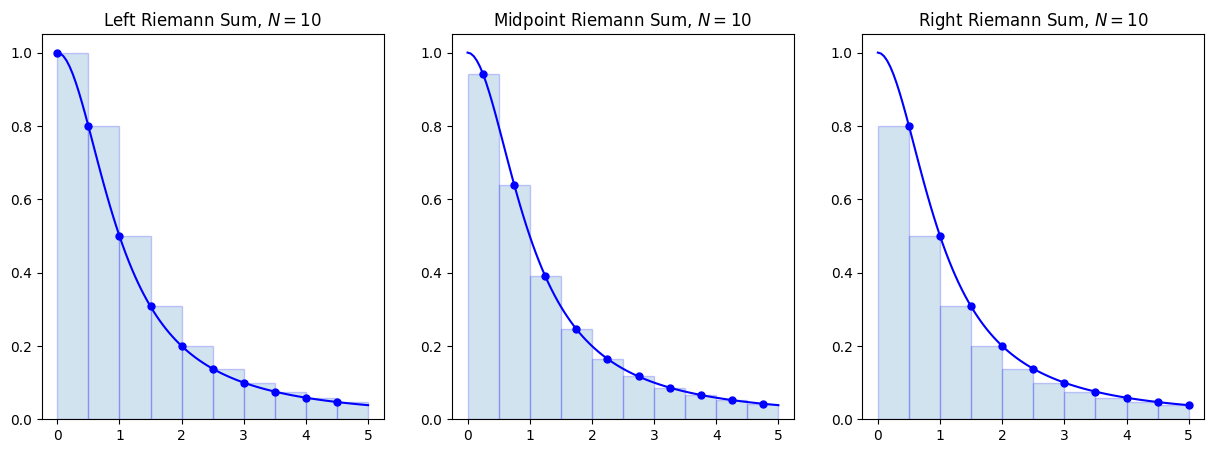

In [1]:
import numpy as np
import matplotlib.pyplot as plt

f = lambda x : 1/(1+x**2)

a = 0; b = 5; N = 10
n = 10 # Use n*N+1 points to plot the function smoothly

x = np.linspace(a,b,N+1)
y = f(x)

X = np.linspace(a,b,n*N+1)
Y = f(X)

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.plot(X,Y,'b')
x_left = x[:-1] # Left endpoints
y_left = y[:-1]
plt.plot(x_left,y_left,'b.',markersize=10)
plt.bar(x_left,y_left,width=(b-a)/N,alpha=0.2,align='edge',edgecolor='b')
plt.title(f'Left Riemann Sum, $N = {N}$')

plt.subplot(1,3,2)
plt.plot(X,Y,'b')
x_mid = (x[:-1] + x[1:])/2 # Midpoints
y_mid = f(x_mid)
plt.plot(x_mid,y_mid,'b.',markersize=10)
plt.bar(x_mid,y_mid,width=(b-a)/N,alpha=0.2,edgecolor='b')
plt.title(f'Midpoint Riemann Sum, $N = {N}$')

plt.subplot(1,3,3)
plt.plot(X,Y,'b')
x_right = x[1:] # Left endpoints
y_right = y[1:]
plt.plot(x_right,y_right,'b.',markersize=10)
plt.bar(x_right,y_right,width=-(b-a)/N,alpha=0.2,align='edge',edgecolor='b')
plt.title(f'Right Riemann Sum, $N = {N}$')

plt.show()

Notice that the left endpoints give an overestimate of the integral, whereas the right endpoints give an underestimate. This could be used as a **simple error estimate**.

Let's compute the value of each of the Riemann sums:

In [2]:
dx = (b-a)/N
x_left = np.linspace(a,b-dx,N)
x_midpoint = np.linspace(dx/2,b - dx/2,N)
x_right = np.linspace(dx,b,N)
I = np.arctan(5)

print(f"Partition with {N} subintervals:")
res = {}
res["left_riemann_sum"] = np.sum(f(x_left) * dx)  # dx could be outside `np.sum`
res["midpoint_riemann_sum"] = np.sum(f(x_midpoint) * dx)
res["right_riemann_sum"] = np.sum(f(x_right) * dx)

for key, val in res.items():
    print(f"{key.replace('_', ' ')}:\t{val:.5f} (error: {val-I:.5f})")

Partition with 10 subintervals:
left riemann sum:	1.61349 (error: 0.24009)
midpoint riemann sum:	1.37354 (error: 0.00014)
right riemann sum:	1.13272 (error: -0.24068)


Note that we assessed the numerical error by comparing to the analytically known result:

$$
\int_0^5 \frac{1}{1 + x^2} dx = \arctan(5)
$$

In [3]:
def riemann_sum(f, a, b, N, method='midpoint'):
    '''Compute the Riemann sum of f(x) over the interval [a,b].

    Parameters
    ----------
    f : function
        Vectorized function of one variable
    a , b : numbers
        Endpoints of the interval [a,b]
    N : integer
        Number of subintervals of equal length in the partition of [a,b]
    method : string
        Determines the kind of Riemann sum:
        right : Riemann sum using the right endpoints
        left : Riemann sum using left endpoints
        midpoint (default): Riemann sum using midpoints

    Returns
    -------
    float
        Approximation of the integral given by the Riemann sum.
    '''
    x, dx = np.linspace(a,b,N+1, retstep=True)
    
    if method == 'left':
        x_left = x[:-1]
        return np.sum(f(x_left)*dx)
    elif method == 'right':
        x_right = x[1:]
        return np.sum(f(x_right)*dx)
    elif method == 'midpoint':
        x_mid = (x[:-1] + x[1:])/2
        return np.sum(f(x_mid)*dx)
    else:
        raise ValueError("Method must be 'left', 'right', or 'midpoint'.")

Let's test our `Python` function with integrals with analytically known values:

$$
\begin{aligned}
I_1 &= \int_0^{\pi/2} \sin(x) \, dx = 1\\
I_2 &= \int_0^1 \frac{4}{1 + x^2} dx = \pi
\end{aligned}
$$

In [4]:
I1_error = riemann_sum(np.sin, 0, np.pi/2, 1000, method="left") - 1
I2_error = riemann_sum(lambda x : 4/(1 + x**2), 0, 1, 1000, method='right') - np.pi
print(f"errors: {I1_error} (I_1) | {I2_error} (I_2)")

errors: -0.0007856037801642346 (I_1) | -0.0010001666666665798 (I_2)


## Trapezoidal Rule

The idea behind the _Trapezoidal rule_ is simple:
<img src="figures/trapezoid.png" style="width:500px;height:500px;" >

It typically gives a better approximation to the integral than the Riemann sum(s).

The interval over which the function is to be integrated is divided into $N$ bins ranging from $x_k=a+kh$, where $k=0,1,\ldots, N$. The lower and upper limits of the integration are $a=x_0$ and $b=x_N=a+Nh$. The integral over each bin, $I_k$, is approximated by a trapezoid as shown above, i.e., 

$$I_k = \underbrace{h \cdot f(x_k)}_{=\mathrm{area\ of\ rectangle}} + \underbrace{{1 \over 2}h \cdot (f(x_{k+1})-f(x_k))}_{=\mathrm{area\ of\ triangle}} 
              = {1 \over 2}h \left ( f(x_k) + f(x_{k+1}) \right ) \,.$$

Recall that the area of a trapezoid is:

$$
A = \frac{m+n}{2} h \,,
$$
where $(m,n)$ are the two bases and $h$ the height of the trapezoid.
              
For the entire integral, we add those contributions from $k=0$ to $k=N-1$ (the last trapezoid starts at $x_{N-1}$). The result is

$$\boxed{I(a,b) \approx \sum_{k=0}^{N-1} I_k = \sum_{k=0}^{N-1}{1 \over 2}h \left ( f(x_k) + f(x_{k+1}) \right ) 
= h \left ( {1 \over 2}f(a) + \sum_{k=1}^{N-1}f(x_{k}) + {1 \over 2}f(b)\right )} $$

Let's ignore for a moment that [`scipy.trapezoid()`](https://docs.scipy.org/doc/scipy-1.16.1/reference/generated/scipy.integrate.trapezoid.html) and [`numpy.trapz()`](https://numpy.org/doc/1.26/reference/generated/numpy.trapz.html) (which is now deprecated) implement the trapezoidal rule and let's implement it ourselves:

### Python program

In [5]:
import numpy as np

# define the function to be integrated
def f(x):
    return x**4  # arbitrary choice, feel free to change
 
# integration limits
a = 0
b = 1

# number of bins
N = 100

# Let's execute first the sum in the trapezoid rule and then add the contributions from
# the endpoints. Note that `linspace(a,b,N)` generates `N` equidistant
# values of x between a,b including the endpoints a and b. This means there are N-1 bins with
# binsize (b-a)/(N-1). 
# If we want to specify N bins we have to use the linspace with the arguments a,b, N+1.
x = np.linspace(a,b,N+1)
y = f(x)
h = (b-a)/N

# let's evaluate the trapezoid rule (using a sliced array)
integral = np.sum(y[1:-1])*h + 0.5 * h*(f(a) + f(b))

# error obtained by comparing with the analytically calculated integral
error_abs = np.abs((b**5-a**5)/5 - integral)

print(f"predicted integral = {integral:1.15e} , error = {error_abs:1.15e}")

predicted integral = 2.000333330000000e-01 , error = 3.333300000002426e-05


Let's us `numpy.trapz()` to check our implementation:

In [6]:
import numpy as np
np.trapz(y=y, dx=h)

/var/folders/7q/6d2x7jlj5rq4ktznvq0xp2xw0000gr/T/ipykernel_17832/1865957360.py:2: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  np.trapz(y=y, dx=h)


np.float64(0.200033333)

Note that we obtain the same result as above. We also get a warning that tells us that `numpy` is going to retire `trapz()` soon in favor of the similar implementation in `scipy`. It's good advise to use `scipy.trapezoid()` instead:

In [7]:
from scipy.integrate import trapezoid
trapezoid(y=y, dx=h)

np.float64(0.200033333)

### Approximation error, Euler-MacLaurin formula

As discussed earlier, there are two types of errors that plague numerical calculations:

1. ***approximation errors*** and   
2. ***round-off errors***. 

**Approximation errors** are because the mathematical expressions we use to calculate the integral are approximate. 

**Rounding errors** are caused by the representation of numbers in your computer as finite bit strings. 

To estimate the approximation error, we have to derive the trapezoidal rule more systematically through Taylor expansions---this way, we know what we miss (i.e., the error term). 

As before, we split the integration interval into small bins ranging from $x_k$ to $x_{k+1}$, calculate the integral over the small bin, and then add the parts. We consider the interval 
$I_{k}\equiv[x_{k} , x_{k+1}]$. We perform a Taylor expansions of the function $f(x)$ for the values of $f$ in $I_{k}$ around $x_{k}$ 

$$
f(x) = f(x_{k})+f^\prime (x_{k}) (x - x_{k}) + {1 \over 2}f^{\prime\prime}(x_{k})(x - x_{k})^2 + \ldots
$$

Such a polynomial can be integrated over the interval $I_{k}$, and we find by elementary steps

$$
\int_{x_{k}}^{x_{k+1}} f(x)dx = hf(x_{k}) +{1 \over 2}h^2 f^\prime (x_{k})
+{1 \over 6}h^3 f^{\prime\prime}(x_{k}) + O(h^4)
$$
                                       
**Now we use a trick.** We expand the function $f$ around the endpoint $x_{k+1}$ of the interval to approximate its values in $I_{k}$, i.e.

$$
f(x) = f(x_{k+1})+f^\prime (x_{k+1}) (x - x_{k+1}) + {1 \over 2}f^{\prime\prime}(x_{k+1})(x - x_{k+1})^2 +\ldots
$$

which also can be integrated over $I_{k}$ easily (again), yielding 

$$
\int_{x_{k}}^{x_{k+1}} f(x)dx = hf(x_{k+1}) - {1 \over 2}h^2 f^\prime (x_{k+1})
+{1 \over 6}h^3 f^{\prime\prime}(x_{k+1}) + O(h^4)
$$
                                       
Adding the two Taylor expansions and dividing by $2$, we find

$$
\int_{x_{k}}^{x_{k+1}} f(x)dx = {1 \over 2} h \left ( f(x_{k}) + f(x_{k+1}) \right )
+{1 \over 4}h^2 \left ( f^\prime (x_{k}) - f^\prime (x_{k+1}) \right )
+{1 \over 12}h^3 \left ( f^{\prime\prime}(x_{k}) + f^{\prime\prime}(x_{k+1}) \right ) + O(h^4)
$$
                                       
Now we add all the pieces together, canceling the $h^2$-terms except for the first and last one (cf. [telescoping series](https://en.wikipedia.org/wiki/Telescoping_series)), and we find

\begin{align}
\int_{a}^{b} f(x)dx &= \sum_{k=0}^{N-1} \int_{x_{k}}^{x_{k+1}} f(x)dx \\
& = {1 \over 2}h \sum_{k=0}^{N-1} \left (f(x_{k})+f(x_{k+1}) \right ) 
+{1 \over 4}h^2 \left ( f^\prime (a) - f^\prime (b) \right ) 
+{1 \over 12}h^3 \sum_{k=0}^{N-1} \left ( f^{\prime\prime}(x_{k}) + f^{\prime\prime}(x_{k+1}) \right ) +O(h^4)
\end{align}

Note that this is an expansion in powers of $h$:

* The **first term** on the right-hand side represents the Trapezoidal rule. The remaining terms describe deviations from the correct result due to higher-order corrections. They represent the ***approximation error***. 
* The **second term** is of the order $h^2$ and hence smaller than the leading order term representing the Trapezoidal rule. 
* The **third term** on the right-hand side appears, at first glance, to be a term of the order $h^3$ and hence even smaller than the previous term, but it is not. The sum over the $N$ terms results in a factor of $N\propto 1/h$, making this term of the same order as the previous term. 

We make the last argument now more quantitative by using the Trapezoidal rule for integrating $f^{\prime\prime}(x)$, which reads in leading order of $h$

$$
\int_a^b f^{\prime\prime}(x)dx \equiv f^{\prime}(b) - f^{\prime}(a) \approx {1 \over 2}h \sum_{k=0}^{N-1} \left ( f^{\prime\prime}(x_{k}) + f^{\prime\prime}(x_{k+1}) \right ) + O(h^2) 
$$

Hence

$$
\begin{aligned}
{1 \over 12}h^3 \sum_{k=0}^{N-1} \left ( f^{\prime\prime}(x_{k}) + f^{\prime\prime}(x_{k+1})\right ) 
&= {1 \over 6}h^2 \cdot {1 \over 2}h \sum_{k=0}^{N-1} \left ( f^{\prime\prime}(x_{k}) + f^{\prime\prime}(x_{k+1})\right ) \\
&= {1 \over 6}h^2 \left ( f^\prime (b) - f^\prime (a) \right ) \\
&= - {1 \over 6}h^2 \left ( f^\prime (a) - f^\prime (b) \right )
\end{aligned}
$$

Combining with the other terms, we find the final **Euler-MacLaurin formula**:

$$
\boxed{\int_{a}^{b} f(x)dx = {1 \over 2}h \sum_{k=0}^{N-1} \left ( f(x_{k})+f(x_{k+1}) \right ) +
{1 \over 12}h^2 \left ( f^\prime (a) - f^\prime (b) \right ) + O(h^4) }
$$

1. **The `Euler-MacLaurin formula` provides us with the approximation error of the Trapezoidal rule.** It tells us that its error is of the order of $h^2$ and, hence, is smaller than the leading-order term. 

2. The leading-order term is actually of the order $h^0$, since the sum provides $N$ terms of the order $1$ resulting in a factor of about $N$ which is proportional to $1/h$ since $h = (a-b)/N$, or $N = (a-b)/h$. 

3. **Note that this equation is only useful if we know the derivative of the integrand function at the boundaries.** Often, this is not the case, for example, if we have the function f only as a set of discrete points. In this case, we will discuss direct methods to estimate the error, which do not require the derivative. 

4. The Trapezoid rule is **particularly accurate** if applied to **periodic functions** and the integration range is the period of the function, since under those circumstances, the error term (see above) and all other higher-order error terms vanish. A generalization of this idea, expanding non-periodic functions into periodic functions through, e.g., a discrete Fourier transformation, results in the so-called *Clenshaw-Curtis quadrature*.  

5. This Taylor expansion can be continued to higher orders, giving rise to the more general form of the Euler-MacLaurin formula. Most importantly, the terms are of the order $h^{2n}$, i.e., **only even orders of $h$**. The next order term amounts to: 

$$ -{h^4 \over 720}\left ( f^{\prime\prime\prime}(a) - f^{\prime\prime\prime}(b) \right )$$

Let's investigate $f(x) = x^4$:

In [8]:
import numpy as np

# define the function to be integrated
def f(x, type="func"):
    if type == "func":
        return x**4
    elif type == "deriv":
        return 4 * x**3
    elif type == "stem":
        return x**5 / 5
    else:
        raise ValueError("wrong specifier")
 
def trapez_mc(a=0, b=1, N=10, f=f, ret_errors=True):
    x, h = np.linspace(a, b, N+1, retstep=True)  # h = (b-a)/N
    integral= h*(sum(f(x)) - 0.5*(f(a) + f(b)))  # Question: Why is there a minus sign in this line?
    # error
    error_abs = abs((f(x=b, type="stem")-f(x=a, type="stem")) - integral)
    error_mc = abs((1/12)*(h**2)*(f(b, type="deriv")-f(a, type="deriv")))
    if ret_errors:
        return integral, error_abs, error_mc, h
    else:
        return integral
    
integral, error_abs, error_mc, h = trapez_mc(a=0, b=1, N=10, f=f, ret_errors=True)
print(f"predicted integral = {integral:1.15e}")
print(f"Error McLaurin = {error_mc:1.15e}")
print(f"actual error = {error_abs:1.15e}")
print(f"binsize = {h:1.15e}")

predicted integral = 2.033300000000000e-01
Error McLaurin = 3.333333333333334e-03
actual error = 3.330000000000000e-03
binsize = 1.000000000000000e-01


This result is important. It tells us that the approximation error decreases by a factor of $4$ if we double the number of bins. This insight is the basis for *adaptive* methods, which are used to compute an integral for a specified accuracy. 

In [9]:
factor=2
integral, error_abs, error_mc, h = trapez_mc(a=0, b=1, N=10, f=f, ret_errors=True)
integral_twice, error_abs_twice, error_mc_twice, h_twice = trapez_mc(a=0, b=1, N=factor*10, f=f, ret_errors=True)
print(f"accuracy increases by a factor of {error_abs/error_abs_twice:.3f} when increasing N by a factor of {factor}")

accuracy increases by a factor of 3.997 when increasing N by a factor of 2


### Round-off error vs approximation error for the example above
**Algorithmic errors decrease with decreasing bin size $h$, whereas round-off errors increase with decreasing bin size since the number of operations increases.** Hence, the sum of the two must have a **minimum** at some value $h_c$. Let's investigate this for the trapezoidal rule:


Text(0, 0.5, 'error')

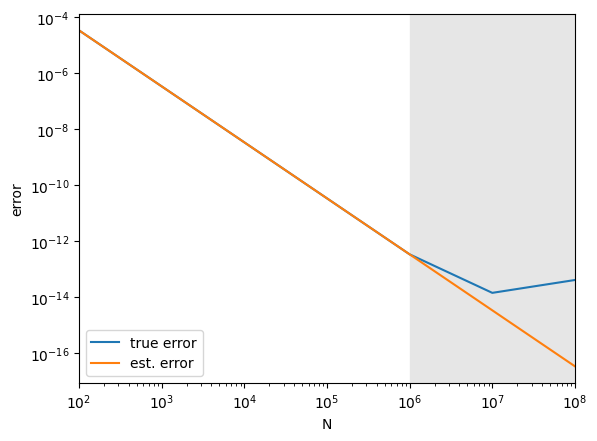

In [10]:
import numpy as np
res = []
for N in np.logspace(2, 8, 7, dtype=int):
    res.append([N, *trapez_mc(a=0, b=1, N=N, f=f, ret_errors=True)])  # Question: what does the "*" do in this line?
res = np.array(res)

import matplotlib.pyplot as plt
plt.loglog(res[:, 0], res[:, 2], label="true error")
plt.loglog(res[:, 0], res[:, 3], label="est. error")
plt.legend(loc="best")
plt.axvspan(10**6, 10**8, color="0.9")
plt.xlim(10**2, 10**8)
plt.xlabel("N")
plt.ylabel("error")

Experimenting with the `Python` program above, we find that if the number exceeds $\approx 10^6 - 10^7$ (gray-shaded region), the actual error starts to exceed the predicted algorithmic error given by the Euler-McLaurin equation, indicating the starting dominance of numerical round-off errors.

For the function $f(x) = x^4$ and $(a=0, b=1)$, we have for the error term:

$$ 
\left | {1 \over 12}h^2 \left ( f^\prime (a) - f^\prime (b) \right ) \right | =  \left | {1 \over 12}h^2 4 \right |  = {1 \over 3}h^2
$$

The value of $h$ at which we see mounting round-off errors is when the expected round-off errors $\sigma_z = \varepsilon \sqrt{N} \sqrt{\bar{x}^2}$ match the algorithmic error. This critical value of $h$, i.e., $h_c \propto N_{opt}^{-1}$ is estimated by

$$ 
{1 \over 3}h_c^2 \approx \varepsilon \sqrt{N_{opt}} \equiv \epsilon h_c^{-1/2}
$$

where we assumed $\bar{x}^2 = \mathcal{O}(1)$. Hence, with $\varepsilon = 10^{-16}$

$$ 
\begin{aligned}
h_c &\approx (3\epsilon)^{2/5} \approx 6.18\cdot 10^{-7} \\
N_{opt} &= {b - a \over h_c} \approx 1.62\cdot 10^6 
\end{aligned}
$$

Let's check these numerical values:

In [2]:
eps = 1e-16
hc = (3*eps)**(2/5)
Nopt = 1/hc
print(f"hc: {hc:.2e}; Nopt: {Nopt:.2e}")

""" Note/Reading stopped here: 9-13-25 PL """

hc: 6.18e-07; Nopt: 1.62e+06


' Note/Reading stopped here: 9-13-25 PL '

### Integration of periodic functions
The Euler-McLauren formula predicts a zero leading order error if the function to be integrated is periodic and the integral is taken over the entire period, $x \in [0,2\pi]$. Let's check that out with a simple periodic function:

$$
f(x) = 1 + \sin(x) + \sin(x)^2
$$

In [12]:
# !pip install sympy  # install sympy if needed
from sympy import Symbol, init_printing, integrate, diff, sin, lambdify
init_printing(use_unicode=False, wrap_line=False)

def f(x, type="func"):
    xv = Symbol('x')
    func = 1 + sin(xv) + sin(xv)**2
    
    if type == "func":
        ret = func
    elif type == "deriv":
        ret = diff(func, xv)
    elif type == "stem":
        ret = integrate(func, xv)
    else:
        raise ValueError("wrong specifier")
    return lambdify(xv, ret, "numpy")(np.atleast_1d(x))

Now, let's plot the three functions:

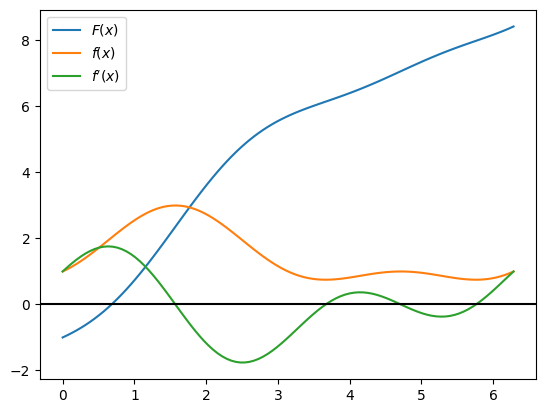

In [13]:
import matplotlib.pyplot as plt
a=0.0
b=2*np.pi
x = np.linspace(a, b, 100)
plt.plot(x, f(x, type="stem"), label="$F(x)$")
plt.plot(x, f(x, type="func"), label="$f(x)$")
plt.plot(x, f(x, type="deriv"), label="$f'(x)$")
plt.axhline(0, c="k")
# plt.xlabel("x")
plt.legend()

In [14]:
integral, error_abs, error_mc, h = trapez_mc(a=a, b=b, N=4, f=f, ret_errors=True)
print(f"predicted integral = {integral[0]:1.15e}")
print(f"Error Euler-McLaurin = {error_mc[0]:1.15e}")
print(f"actual error = {error_abs[0]:1.15e}")
print(f"bin size = {h:1.15e} (= {h/np.pi:.2} pi)")

predicted integral = 9.424777960769379e+00
Error Euler-McLaurin = 9.131218375025986e-17
actual error = 0.000000000000000e+00
bin size = 1.570796326794897e+00 (= 0.5 pi)


We find that for $N\geqslant 4$, i.e., for a bin size less than $\pi/2$, we find the value of the integral less than machine precision. This is very remarkable at first glance. 

The reason for this remarkable result is that the equation for the Trapezoid rule is **exact**, i.e., there are no algorithmic errors, **if** the bin size is chosen according to the *sampling theorem* or also known as *Nyquist Theorem*: 

> [**Nyquist theorem**](https://en.wikipedia.org/wiki/Nyquist%E2%80%93Shannon_sampling_theorem):   
> **If a function $f(t)$ has bandwidth $B$, which indicates the highest frequency it contains, it is completely represented by sampling it with a sampling rate $f_s > 2B$.** That is, the sampling points are spaced less than $f_s^{-1}$ apart.


> **Shannon's (alternative) version**:    
> If a function $f( t )$ contains no frequencies higher than $B$, then it can be completely determined from its ordinates at a sequence of points spaced less than $1 / ( 2 B )$ apart. 

So let's see what the Nyquist theorem offers for our **example above**. The period of the function is $T = 2\pi$, i.e., the basic frequency is $f_0 = 1/T = 1/(2\pi)$.
With

$$
\sin^2(x) = {1 \over 2}\left ( 1 - \cos(2x) \right )
$$

we see that the highest frequency contained in the function, i.e., the bandwidth $B = 2f_0 = 1/\pi$. 

Hence:
$$
h = \frac{2\pi}{N} < \frac{1}{2B} = \frac{\pi}{2} \quad \Leftrightarrow \quad N > 4 
$$
which is what we found empirically. 

In practice, **there may not be an exact finite bandwidth**, and hence, the theorem in its pure form cannot predict an exact value for $N$. But even if you violate the Sampling theorem a little bit, you can get integrals with remarkable precision. 

Below we study the example:

$$
\int_{-\pi}^\pi \exp(\cos(x))dx = 2\pi I_0(1)
$$

where $I_0(x)$ denotes the **modified Bessel function** with index $0$. The integrand has no exact finite bandwidth, so we just try what values of $N$ work. 

We find that for $N > 15$, the predicted value of the integral is already within machine precision. 


In [15]:
import numpy as np
# define the function to be integrated
def f(x, alpha):
    return np.exp(alpha*np.cos(x))

# integration interval and bin size
a=-np.pi
b=np.pi
N=5
h=(b-a)/N
alpha = 1

# exact integral
exact_int = 2*np.pi*np.i0(alpha)

# Integral with Trapezoid rule
integral= h*(sum(f(np.linspace(a,b,N+1),alpha))- 0.5*(f(a,alpha) + f(b,alpha)))

print(f"pred. integral:\t{integral:1.15e}")
print(f"exact integral\t{exact_int:1.15e}")
                     
# error
error_abs = abs(exact_int - integral)
print(f"actual error:\t{error_abs:1.15e}")
print(f"bin size:\t{h:1.15e}")

pred. integral:	7.951515217846403e+00
exact integral	7.954926521012844e+00
actual error:	3.411303166441115e-03
bin size:	1.256637061435917e+00


## Simpson Rule
For smooth functions, we can use a more accurate algorithm that uses fewer bins to achieve the required accuracy. While roundoff errors were not significant in the previous example, they can become a problem for longer integration intervals. 

Higher-order algorithms will help here to keep the number of bins smaller.


The Trapezoidal rule is a *2-point* rule, where we use two subsequent points and their functions to approximate the integral over each subinterval. 

The **Simpson Rule is a *3-point* rule**, where we use three subsequent points. 

The basic idea is quite simple. The integration interval is divided into $N$ bins starting at $x_k = a + kh$, where $k=0,1,2,\ldots,N-1,N$. Specifically $x_0=a,x_N=b$.

<img src="figures/Simpson-2.png" style="width:500px;height:450px;" >

**Note that the number of bins $N$ is even.**

We will use three sequential points and fit a second-order polynomial, i.e., $f(x)\approx c_2(x-x_k)^2+c_1(x-x_k)+c_0$, through those three points. Hence, we have 3 constraints for 3 unknowns in the linear system:

\begin{align}
f(x_k) &= c_2(x_k-x_k)^2+c_1(x_k-x_k)+c_0 \equiv c_0 \\
f(x_{k\pm 1}) &= c_2 \underbrace{(x_{k\pm 1}-x_k)^2}_{=h^2} + c_1 \underbrace{(x_{k\pm 1}-x_k)}_{=\pm h}+c_0
\end{align}

For each interval, the three constants $c_0,c_1$ and $c_2$ are then uniquely determined by

$$
\begin{aligned}
c_2 &= {1 \over 2 h^2} \left ( f(x_{k-1}) - 2f(x_k) + f(x_{k+1} )\right ) \\
c_1 &= {1 \over 2h}\left ( f(x_{k+1}) - f(x_{k-1}) \right )
\\
c_0 &= f(x_k)
\end{aligned}
$$

The function in the interval $[x_{k-1},x_{k+1}]$ is thus approximated by a **second-order polynomial**, which can be integrated to obtain an approximation for the integral in this interval

$$
I_k = \int_{x_{k-1}}^{x_{k+1}} f(x)dx \approx {1 \over 3}h \left ( f(x_{k-1}) + 4f(x_k) +f(x_{k+1}) \right ) 
$$

What is left to do now is to add all those values over the entire domain of integration, resulting in even $N$ in

$$ 
I(a,b) = {1 \over 3}h \left[ f(a) + 4f(x_1) +f(x_2) +f (x_2) +4f(x_3) + f(x_4) + \ldots +f(x_{N-2} + 4f(x_{N-1}) + f(b) \right]
$$

$$
\boxed{I(a,b) = {1 \over 3}h \left[ f(a) + 4\underbrace{\sum_{k=1}^{N-1}f(a+kh)}_{k~ \rm {odd}} + 
\underbrace{2\sum_{k=2}^{N-2}f(a+kh)}_{k~ \rm{even}} + f(b) \right]}
$$

By construction, the number of bins $N$ is an even number because we use 2 bins for each sub-integral (i.e., 3-point rule).

Let's check our expressions for the second-order polynomial using symbolic calculations with `sympy`.

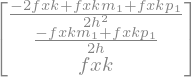

In [16]:
from sympy import symbols
from sympy.matrices import Matrix
xkm1,xk,xkp1,fxkm1,fxk,fxkp1,h = symbols("xkm1,xk,xkp1,fxkm1,fxk,fxkp1,h")
xkm1, xkp1 = xk - h, xk + h
row = lambda x: [x**2, x, 1]
A = Matrix([row(xkm1-xk), row(0), row(xkp1-xk)])
b = Matrix([fxkm1,fxk,fxkp1])
cvec = A.solve(b)
cvec

Note that these expressions match the ones above! What does the variable `fxk` stand for?

### Python Program

In [17]:
from numpy import arange,sin,pi

# define the function to be integrated
def f(x):
    return x**4

# integration interval and bin size
a=0
b=1
N=10  # number of bins must be even
h=(b-a)/N

# execute Simpson with array-operations (without boundaries)
# x_odd = np.linspace(a+h, b-h, N//2)
# x_even = np.linspace(a+2*h, b-2*h, N//2-1)

# more elegantly, using index slicing
x_all = np.linspace(a, b, N+1)
x_odd = x_all[1:-1:2]
x_even = x_all[2:-2:2]

y_all = f(x_all)
y_odd = y_all[1:-1:2]
y_even = y_all[2:-2:2]
integral=h*(1./3.)*(y_all[0]+y_all[-1]+4*sum(y_odd)+2*sum(y_even))
error_act = abs(0.2 - integral)
error_pre = 24/180*h**4  # see below
print(f"pred. integral:\t{integral:1.15e}")
print(f"actual error:\t{error_act:1.15e}")
print(f"est. error:\t{error_pre:1.15e}")

pred. integral:	2.000133333333333e-01
actual error:	1.333333333333742e-05
est. error:	1.333333333333333e-05


`scipy` implements the Simpson rule in `scipy.integrate.simpson(y, x=None, *, dx=1.0, axis=-1)`. Note that `simpson()` used to have `even=None` as a keyword argument. See [here](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.simpson.html) for the documentation. 

Let's check that our implementation is correct:

In [18]:
from scipy.integrate import simpson
res = simpson(y=y_all, x=x_all)
print("pred. integral:", res)
np.isclose(integral, res)

pred. integral: 0.20001333333333335


np.True_

What happens if $N$ is not even? Hint: see the documentation!

### Approximation error
A similar calculation as for the Trapezoidal rule can be done for the Simpson rule, resulting in 

$${\rm error} = {1 \over 180}h^4 \left ( f^{\prime\prime\prime}(a) - f^{\prime\prime\prime}(b) \right )$$

which tells us that the **Simpson method is a fourth-order method** - two orders better than the Trapezoid rule. 

## Richardson extrapolation and error estimates
The Trapezoidal and Simpson rules can be used to integrate functions given **in the form of data sets**, i.e., the function is given at discrete points. While applying the Trapezoidal rule is straightforward, estimating errors is not straightforward because the Euler-MacLaurin equation contains derivatives of the function to be calculated at the interval ends. 

**Here, we talk about a simple method to estimate the errors if the data are discrete.**

1) We pick an initial number of bins, $N_1$, resulting in a bin size of $h_1=(b-a)/N_1$, and we execute the Trapezoidal rule to obtain a first estimate $I_1$. We know, of course, that this is not the exact integral $I$, so that
$$
I = I_1 + \epsilon_1 \approx I_1 + c_1 h_1^2
$$
where $c_1$ is some to be determined constant. **Since we only have data, we can't use the Euler-Maclaurin expression.** 

2) We repeat the process with $N_2 = 2N_1$ bins and a bin size of $h_2 = h_1/2$. This yields yet another estimate of the integral 

$$I = I_2 + \epsilon_2 \approx I_2 + c_1 h_2^2 $$

3) We can now eliminate the unknown exact integral $I$, to resolve for the unknown constant $c_1$, i.e.
$$
I_2 - I_1 = \epsilon_{1} - \epsilon_{2} \approx c_1h_{1}^2 - c_1 h_{2}^2 = 4c_1 h_2^2 - c_1 h_2^2 = 3 c_1 h_2^2 
$$
and hence we have learned the unknown constant from the two separate integrations:
$$
c_1 \approx {I_{2} - I_{1} \over 3h_2^2}~.
$$ 
Hence the error
$$ 
\boxed{\epsilon_2 \approx c_1h_2^2 = {1 \over 3}(I_2 - I_1)}~.
$$

In conclusion, we now have a **simple way to estimate the error** of the integral estimate (also known as **Richardson extrapolation**).
We also have a more accurate value of the integral

$$ \boxed{I \approx I_2 + c_1h_2^2 = I_2 + {1 \over 3}(I_2 - I_1) + \mathcal{O}{(h_2^4)} \equiv \frac{1}{3} \left( 4I_2 - I_1 \right) + \mathcal{O}{(h_2^4)}} $$

In [19]:
import numpy as np

# define the function to be integrated
def f(x):
     return x**4

# define the Trapezoidal program as a function
def trapezoidal(f,a,b,N):
    grid, h = np.linspace(a,b,N+1, retstep=True)
    assert np.isclose(h, (b - a)/N, rtol=1e-12, atol=1e-12)
    return h*(sum(f(grid))- 0.5*(f(a) + f(b)))

# parameters
a=0
b=1
N1=10
N2 = 2*N1

I1=trapezoidal(f,a,b,N1)
I2=trapezoidal(f,a,b,N2)

# predicted errors
error_est = abs((1./3.)*(I2 - I1))  ## epsilon_2
error_act = abs((b**5-a**5)/5 - I2)
error_Eul = (1/12)*((b-a)/N2)**2*(4)

# errors in trapezoid predictions
print(f"estimated error (from I2 - I1)  = {error_est:1.15e}")
print(f"actual error (from I2) = {error_act:1.15e}")
print(f"Euler-MacLaurin error (from I2) = {error_Eul:1.15e}")
print("------------------------------------------")

# Richardson extrapolation
R21 = I2 + (1./3.)*(I2 - I1)
error = abs(R21-0.2)
print(f"improved integral={R21: 1.15e}")
print(f"error = {error:1.15e}")

estimated error (from I2 - I1)  = 8.322916666666513e-04
actual error (from I2) = 8.331250000000456e-04
Euler-MacLaurin error (from I2) = 8.333333333333335e-04
------------------------------------------
improved integral= 2.000008333333334e-01
error = 8.333333333943038e-07


This equation now is a 4-th order algorithm similarly accurate as the Simpson rule.

## Adaptive Trapezoidal rule
If the above solution is still not precise enough, **the process above can be continued to smaller and smaller steps and higher accuracy.**

We generalize the process above with $N_i=2^{i-1}N_1$ and $h_i = 2^{1-i}h_1$ and $i=2,3,\ldots$. This yields a **series of second-order estimates** $I_i$ for decreasing bin sizes

\begin{align}
I &= I_{i-1} + \epsilon_{i-1} = I_{i-1} + c_1 h_{i-1}^2 \\
I &= I_i + \epsilon_i = I_i + c_1 h_i^2
\end{align}

Subtracting equations with $I_i$ associated with the bin size $h_i$ and $I_{i-1}$ associated with the bin size $h_{i-1}=2h_i$, the exact integrals $I$ (we don't know) cancel, and we find

$$
I_i - I_{i-1} = \epsilon_{i-1} - \epsilon_{i} = c_1h_{i-1}^2 - c_1 h_{i}^2 = 4c_1 h_i^2 - c_1 h_i^2 = 3 c_1 h_i^2 = 3\epsilon_i
$$

or finally, for the second-order error

$$ 
\boxed{\epsilon_i = {1 \over 3} \left ( I_i - I_{i-1} \right ) ~~,~~ i=2,3,\ldots }
$$

Since we have a way of estimating errors, we can now accomplish the goal of calculating an integral to a certain accuracy without knowing the exact value of the integral. The procedure is quite simple:

1. Evaluate the integral using the trapezoidal rule to obtain $𝐼_1$ with  $𝑁_1$ bins.
2. Evaluate the integral with the Trapezoidal rule with $𝑁_2=2N_1$  bins to obtain $𝐼_2$ and evaluate the error  $\epsilon_2=(1/3)(𝐼_2−𝐼_1)$. The current best estimate for the integral is $I\approx I_2 + \epsilon_2$.
3. If the error is too large, calculate $𝐼_3$ with $𝑁_3=2𝑁_2=4𝑁_1$ bins. Using the above equation, the error is $\epsilon_3=(1/3)(𝐼_3−𝐼_2)$ and the current best estimate for the integral is $I\approx I_3 + \epsilon_3$.
4. Repeat the process until the error is as small as requested. **Each step forward requires only a single new Trapezoid integration.**

In [20]:
import numpy as np

# define the function to be integrated
def f(x):
     return x**4

# define the Trapezoidal program as a function
def trapezoidal(f,a,b,N):
    grid, h = np.linspace(a,b,N+1, retstep=True)
    # assert np.isclose(h, (b - a)/N, rtol=1e-12, atol=1e-12)
    return h*(sum(f(grid[1:-1])) + 0.5*(f(a) + f(b)))

# integration interval
a=0
b=1
N1=10
N2=2*N1
I_exact = (b**5 - a**5)/5

# maximum error
error_max=1e-8

y1=trapezoidal(f,a,b,N1)
y2=trapezoidal(f,a,b,N2)
error_est = (1./3.)*abs((y2-y1))
print(f"N = {N2} , I = {y2:1.15e}, error = {error_est:1.15e}")
N_array = []
err_array = []
while error_est > error_max:  # better: add safeguard here to avoid infinite loops
    y1 = y2
    N1 = N2
    N2 = 2*N1
    y2 = trapezoidal(f,a,b,N2)
    error_est = (1./3.)*abs((y2-y1))
    error_act = abs(y2-I_exact)
    N_array.append(N2)
    err_array.append(error_act)
    print(f"N = {N2} , I = {y2:1.10e}, error = {error_est:1.10e}, error_act {error_act:1.10e}")

N = 20 , I = 2.008331250000001e-01, error = 8.322916666666513e-04
N = 40 , I = 2.0020832031e-01, error = 2.0826822917e-04, error_act 2.0832031250e-04
N = 80 , I = 2.0005208252e-01, error = 5.2079264323e-05, error_act 5.2082519531e-05
N = 160 , I = 2.0001302078e-01, error = 1.3020579020e-05, error_act 1.3020782471e-05
N = 320 , I = 2.0000325521e-01, error = 3.2551924388e-06, error_act 3.2552051545e-06
N = 640 , I = 2.0000081380e-01, error = 8.1380108993e-07, error_act 8.1380188469e-07
N = 1280 , I = 2.0000020345e-01, error = 2.0345045878e-07, error_act 2.0345050836e-07
N = 2560 , I = 2.0000005086e-01, error = 5.0862626305e-08, error_act 5.0862629442e-08
N = 5120 , I = 2.0000001272e-01, error = 1.2715657286e-08, error_act 1.2715657582e-08
N = 10240 , I = 2.0000000318e-01, error = 3.1789146870e-09, error_act 3.1789135213e-09


The true value is $I=0.2$.

Text(0, 0.5, 'error')

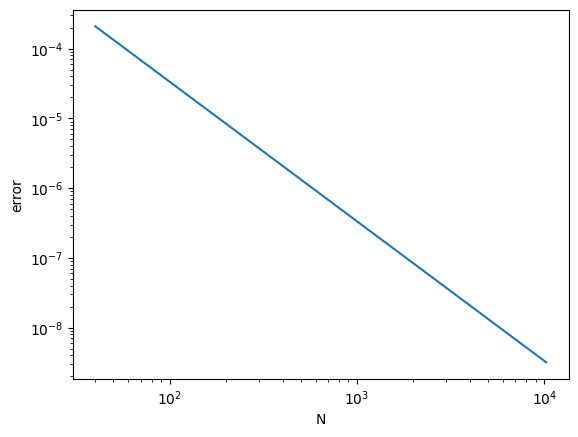

In [21]:
import matplotlib.pyplot as plt
plt.loglog(N_array, err_array)
plt.xlabel("N")
plt.ylabel("error")

While the goal of reaching a given accuracy has been achieved, it has been achieved **very slowly and with a significant computational cost**. Notice that we evaluated the function (more than) $n=10240$ times.

**We can do much better and faster by utilizing Richardson extrapolation for an adaptive algorithm.**

## Trapezoidal rule on steroids: Romberg Method
The Romberg method is based on the Trapezoidal rule and the corresponding error analysis. 

In contrast to the simple adaptive Trapezoide rule, it constructs higher-order estimates of the integral ($h^2,h^4,h^6,\ldots$) by **smart recycling of Trapezoidal integrations**. 

### 4-th order Romberg method
**We proceed exactly as before, but will use a different notation.** We start by computing the integral with step sizes of $h_1$ and $h_2 = h_1/2$ using the Trapezoidal rule. (That is, our notation uses step sizes rather than the number of intervals.)

This index will result in the two corresponding estimates for the integral $T_{11}$ and $T_{21}$. 
* The **first index** represents the `step size`.
* The **second index** indicates the `order` of the error.

We start with the first order

\begin{align}
I &= T_{11}+ c_1h_1^2 \equiv T_{11} + 4c_1h_2^2 \\
I &= T_{21} + c_1h_2^2
\end{align}

Just like before, we find the value of $c_1$ by subtracting these equations, resulting in 

$$ 
c_1 h_2^2 = {1 \over 3} \left ( T_{21} - T_{11} \right )
$$ 

which is the estimated error of the second-order estimate. It also allows for a 4th-order estimate of the integral

$$
\boxed{ 
I = \underbrace{T_{21} + {1 \over 3}\left ( T_{21} - T_{11} \right )}_{\equiv T_{22}} + \mathcal{O}(h_2^4) = T_{22} + c_2 h_2^4 }
$$

This is already a 4th-order estimator for the integral. Note that the coefficient in the 4th order error is different from that of the second order coefficient. 

All we have used at this point are the two second-order Trapezoid calculations $T_{11}$ and $T_{21}$. Just to make clear:
* the first index of $T_{ij}$ denotes the **step size** we used, i.e. $h_i = h_1/2^{i-1}$ while 
* the second index indicates the **order** of the expression, in this case $2j$.  

While we do know the order of the algorithm, we don't know (yet) the estimated error. To calculate the error, we follow the same approach as for the Trapezoid rule: we calculate $T_{22}$ for a smaller stepsize (half the original), which is also necessary to derive the 6th-order expression. 

### 6-th Order Romberg method
We now want to calculate the term $c_2h_2^4$ so that the remaining error is of 6-th order in the step size. 

To do this, we calculate another expression $T_{32}$, which is like $T_{22}$, but with a step size of $h_3 = h_2/2 =h_1/4$. 

$$ 
T_{32}\equiv T_{31} + {1 \over 3}\left ( T_{31} - T_{21} \right )
$$

which requires only one new Trapezoid integral calculation $T_{31}$ with a step size of $h_3$.

Comparing now

\begin{align}
I &= T_{22} + c_2h_{2}^4 \equiv T_{22} + 2^4\,c_2h_3^4\\
I &= T_{32} + c_2h_{3}^4
\end{align}

we can resolve for $c_2h_3^4$, i.e.

$$ 
c_2h_3^4 = {1 \over 2^4-1}\left ( T_{32}-T_{22} \right ) 
$$

and find for the integral $I$

$$
\boxed{
I =  \underbrace{T_{32} + {1 \over 2^4 - 1} 
\left ( T_{32} - T_{22}\right )}_{=T_{33}}+ \mathcal{O}(h_3^6) \equiv T_{33} + c_3h_3^6}
$$

Note that:
* The only new calculation we had to do was the Trapezoid integral $T_{31}$ with a stepsize $h_3 = h_2/2$.
* In total, only 3 Trapezoid computations were necessary to obtain this 6th-order estimate. 

The error of the 4th-order expression can now also be obtained

$$
\boxed{
c_2h_2^4 = 2^4 \, c_2h_3^4 = {2^4 \over 2^4-1} \left ( T_{32}-T_{22} \right ) }
$$

It is now clear that we can **continue with this procedure to arbitrary order**. One can either use the Romberg method at a **fixed order** or one can continue to go to higher orders until a given accuracy is reached (**adaptive Romberg**). 

In order to find the error of the 6-th order estimate, i.e., $c_3h_3^6$, we have to calculate another 6-th order estimate $T_{43}$ with a smaller stepsize of $h_4 = h_3/2$ or $h_3 = 2h_4$

$$
I = T_{43} + c_3h_4^6
$$

and compare to the previous

$$
I = T_{33} + c_3h_3^6 = T_{33} + 2^6 c_3h_4^6
$$

eliminating $I$ we find

$$
c_3h_4^6 = {1 \over 2^6 - 1}\left (T_{43} - T_{33} \right )
$$

and for the desired error of the third-order estimate

$$
\boxed{
c_3h_3^6 = 2^6 c_3h_4^6 = {2^6 \over 2^6 -1} \left (T_{43} - T_{33} \right )}
$$

with

\begin{align}
T_{43} &= T_{42} + {1 \over 2^4-1} \left ( T_{42} - T_{32}\right )\\
T_{42} & \equiv T_{41} + {1 \over 3}\left ( T_{41} - T_{31} \right )
\end{align}

which means that only one additional Trapezoid calculation $T_{41}$ is necessary.

In [22]:
# Romberg Integration 6th order
import numpy as np

# define the function to be integrated
def f(x):
    return np.exp(x)

# define the Trapezoidal program as a function
def trapezoidal(f,a,b,N):
    h = (b - a)/N
    return h*(sum(f(np.linspace(a,b,N+1)))- 0.5*(f(a) + f(b)))

# Romberg method 6-th order
def Romberg6(f,a,b,N):    
    # Calculate the second-order integrals T_11,T_21,T_31
    T_11 = trapezoidal(f,a,b,N)
    T_21 = trapezoidal(f,a,b,2*N)
    T_31 = trapezoidal(f,a,b,4*N)
    T_41 = trapezoidal(f,a,b,8*N)
   
    # Calculate the 4-th order integrals
    T_22 = T_21 + (1.0/3.0)*(T_21 - T_11)
    T_32 = T_31 + (1.0/3.0)*(T_31 - T_21)
    T_33 = T_32 + (1.0/15.0)*(T_32 - T_22)
    T_42 = T_41 + (1.0/3.0)*(T_41 - T_31)
    T_43 = T_42 + (1.0/15.0)*(T_42 - T_32)

    error = (64/63)*(T_43 - T_33)
    return(T_33,error)

# integration interval: a,b
a=0
b=5
N=100

exact = np.exp(b)-1
integral,error = Romberg6(f,a,b,N)
print(f"integral =\t{integral:1.16e}")
print(f"error_est =\t{error:1.15e}")
print(f"error_act =\t{abs(exact-integral):1.16e}")

integral =	1.4741315910257774e+02
error_est =	-1.097168211662580e-12
error_act =	1.1368683772161603e-12


**In general, Romberg quadrature works as follows:**

* Apply the trapezoidal rule $T=T(h)$ with step sizes $\left( h_i \right)_{i=1, \, \ldots \, ,m}$. This defines $ T_{i,1}:=T(h_i) \, , i=1, \, \ldots \, ,m \, .$
* Evaluate the so-called Neville-Aitken algorithm:           
$$                
T_{i,k} := T_{i,k-1} + 
    \frac{ T_{i,k-1}-T_{i-1,k-1} }
    { \left( 
        \frac{ h_{i-k+1} }{ h_i } 
    \right)^2 -1 }
    \, \quad
    \text{with}
    \quad
    2 \leq k \leq i
    \, .
$$
* The output translates to the lower-triangular matrix:
\begin{matrix}
T_{1,1} \\
&\searrow \\
T_{2,1} & \rightarrow & T_{2,2} \\
\vdots  & & & \ddots \\
T_{k-1,1} & \rightarrow & \cdots & \rightarrow & T_{k-1,k-1} \\
&\searrow & & \searrow & & \searrow \\
T_{k,1} & \rightarrow & \cdots & \rightarrow & T_{k,k-1} & \rightarrow & T_{k,k} \, .
\end{matrix}
Note that the first column corresponds to the Trapezoidal rule evaluations (i.e., $T_{j1}$). The other columns are obtained using Richardson extrapolation (i.e., $T_{ij}$). The diagonal elements $T_{jj}$ provide the best estimate at each iteration.

Romberg quadrature is [implemented](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.romb.html) in `scipy`:
```python
scipy.integrate.romb(y, dx=1.0, axis=-1, show=False)
```
**Parameters:**
- `y`: A vector of `2**k + 1` equally-spaced samples of a function.
- dx The sample spacing. Default is `1`.
- If `show=True`, the lower-triangular matrix above will be printed. That is, the components of the 2-tensor `T`.

In [23]:
import numpy as np
from scipy.integrate import romb
Nfunc = 2**6+1
print(f"Number of function evals: {Nfunc}")
x, h = np.linspace(a, b, Nfunc, retstep=True)
print(f"Smallest stepsize: {h}\n")
y = f(x)
res = romb(y, dx=h, show=True)
print(res)

Number of function evals: 65
Smallest stepsize: 0.078125

Richardson Extrapolation Table for Romberg Integration
373.53290 
217.22268 165.11928 
166.12562 149.09327 148.02487 
152.18081 147.53254 147.42849 147.41903 
148.61086 147.42088 147.41344 147.41320 147.41317 
147.71295 147.41365 147.41316 147.41316 147.41316 147.41316 
147.48813 147.41319 147.41316 147.41316 147.41316 147.41316 147.41316 
147.41315910257802


**How are the numbers in each column obtained? What error scalings do they have?**

In [24]:
import numpy as np
I_exact = np.exp(b)-np.exp(a)
T_44 = 147.41903
T_71 = 147.48813
print(f"Error of Richardson extrapolation with 8 steps {np.abs(T_44-I_exact):e} vs error of 64-step trapezoidal rule {np.abs(T_71-I_exact):e}")

Error of Richardson extrapolation with 8 steps 5.870897e-03 vs error of 64-step trapezoidal rule 7.497090e-02


As we can see, Richardson extrapolation with 8 steps is more accurate than a single high-order (64-step) trapezoidal rule.

Romberg quadrature used to be [implemented](https://docs.scipy.org/doc/scipy-1.12.0/reference/generated/scipy.integrate.romberg.html) in `scipy` as:
```python
scipy.integrate.romberg(function, a, b, args=(), tol=1.48e-08, rtol=1.48e-08, show=False, divmax=10, vec_func=False)
```
However, this function is now deprecated. The output of `show=True` was more comprehensive:

![](figures/scipy-romberg.png)


In [25]:
# Feel free to switch to a previous version of `scipy` and run the following:
# import numpy as np
# from scipy.integrate import romberg
# res = romberg(f, a, b, show=True)
# print(res)

## Gaussian Quadrature
The basic idea of Gaussian quadrature is to **fit a polynomial to the function to be integrated**, i.e., $f(x)$, and then integrate the polynomial. The difference from previous methods is that we let the grid points $x_k$ at which we evaluate the function, i.e., $f(x_k)$, are **not equally spaced**. 

<img src="figures/Interpolation-sketch.png" style="width:500px;height:400px;" >

### Lagrange interpolation formula

We know the function $f(x)$ at the values of $x_1,x_2,\ldots,x_N$, i.e. $f(x_i)=f_i$, for $i=1,2,\ldots,N$. Let's interpolate the functions using a polynomial of degree $N-1$ (e.g., $N$ points are needed for constructing a polynomial of degree $N-1$). 

To this end, we define the polynomial of degree $N$

$$
\pi(x) = (x-x_1)(x-x_2)\ldots (x-x_i)\ldots (x-x_{N-1})(x-x_N)
$$

with zeros at the above-mentioned values $x_k$. 

We now need the **derivatives** of $\pi(x)$ at the grid points $x_i$. The derivative of this function is obtained using the product rule resulting in a sum of polynomials of order $N-1$. 

At a grid point $x_i$, however, only one of those terms in the sum is not zero, namely the term that was differentiated "away" with the product rule, i.e.

$$
\pi^\prime(x_i) = (x_i - x_1)(x_i - x_2)\ldots (x_i - x_{i-1})\times(x_i - x_{i+1}) \ldots (x_i - x_{N-1})(x_i - x_N) 
$$

With those two functions in place, **we now define $N$ new polynomials of degree $N-1$**

$$ 
l_i(x) \equiv {\pi(x) \over (x-x_i)\pi^\prime(x_i)}~.
$$ 

We now consider the values of $l_i(x)$ at the grid points, i.e., $l_i(x_j)$.

In the case $j=i$, the term $x-x_i$ in $\pi(x)$, although of zero value, cancels with the term $x-x_i$ in the
denominator of $l_i(x)$, and the remaining terms $(x_i-x_{m\ne i})$ will cancel with the equivalent terms in $\pi^\prime(x_i)$, resulting in unity, i.e.,

$$ l_i(x_i) = 1$$

In the other cases of $j\ne i$,the function $l_i(x_j)$ will vanish because of $\pi(x_j) = 0$, i.e.,

$$l_i(x_{j\ne i}) = 0~, $$

or briefly

$$\boxed{l_k(x_{m}) = \delta_{km} } . $$ 

Hence, **the interpolating polynomial $y(x)$ of degree $N-1$** that assumes the values $f(x_i)$ at the values $x_i$ is given by 

$$
\boxed{y(x) = \sum_{i=1}^N f(x_i)l_i(x)}
$$

with

$$ 
y(x_m) = \sum_{i=1}^N f(x_i)\underbrace{l_i(x_m)}_{=\delta_{im}} = f(x_m)
$$

**The degree of the interpolating polynomial is $N-1$**, i.e., one less than the number of grid points $x_i$. That is because, e.g., two grid points are needed for a linear interpolation, i.e., a polynomial of degree 1. 


Without proof, the truncation error at a given value of $x$ is proportional to the $N$-th derivative of the function $f(x)$, i.e., the **Lagrange remainder**:

$$ \boxed{
E(x) = \pi(x){f^{(N)}(\xi) \over N!}}
% \label{error1}
$$

where $\xi$ is some number in the interval $[x_1,x_N]$ (cf. [mean value theorem](https://en.wikipedia.org/wiki/Mean_value_theorem) and [estimation of the Taylor remainder](./taylor_remainder.pdf) as a refresher). This is the famous **Lagrange interpolation formula**.

We note:
* The errors obviously vanish at the grid points because $y(x_i) = f(x_i)$ by construction. 
* If the function $f(x)$ is a polynomial of degree $N-1$ or less, the interpolation error is zero because then the interpolating polynomial is identical to that function. 
* Lagrange interpolation is implemented in [`scipy.interpolate.lagrange(x, w)`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.lagrange.html). Question: what is the second argument `w` for?

#### Examples
We are starting with a smooth function, the sine-squared function. 

number of requested grid points: 9


Text(0, 0.5, 'f(x)')

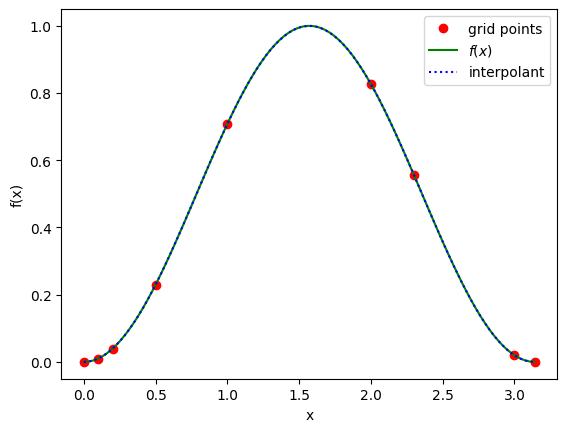

In [26]:
# Lagrange interpolation
import numpy as np
from scipy.interpolate import lagrange
import matplotlib.pyplot as plt

# generate data points
def f(x):
    return np.sin(x)**2
    
x_dis = np.array([0.0, 0.1, 0.2, 0.5, 1, 2, 2.3, 3, 3.14])  # np.linspace(0, np.pi, 10)
print(f"number of requested grid points: {len(x_dis)}")
f_dis = f(x_dis)

#plot grid points and function
plt.plot(x_dis, f_dis, "ro", label="grid points")
xc = np.linspace(0, np.pi, 100)
plt.plot(xc, f(xc), "g-", label="$f(x)$")

# construct and plot Lagrange interpolant
poly = lagrange(x_dis, f_dis)
plt.plot(xc, poly(xc), "b:", label="interpolant")

plt.legend()
plt.xlabel("x")
plt.ylabel("f(x)")

In [27]:
for x_star in x_dis:
    print(f"the interpolation error is at x = {x_star} is {poly(x_star) - f(x_star)}.")

the interpolation error is at x = 0.0 is 0.0.
the interpolation error is at x = 0.1 is 2.6020852139652106e-17.
the interpolation error is at x = 0.2 is 1.5959455978986625e-16.
the interpolation error is at x = 0.5 is 2.0539125955565396e-15.
the interpolation error is at x = 1.0 is 1.2212453270876722e-14.
the interpolation error is at x = 2.0 is -7.627232179174825e-14.
the interpolation error is at x = 2.3 is -2.383648833870211e-13.
the interpolation error is at x = 3.0 is -1.229554652537601e-12.
the interpolation error is at x = 3.14 is -1.561370420264253e-12.


**The (low-order) interpolation does well in reproducing the original function.** (But be aware of the numerical errors toward the right end of the interpolation interval.) Therefore, it is expected that integrating the interpolating function will also be a good approximation to the integral. The interpolation is poor for not-so-smooth functions, such as rugged experimental data.

However, if too many grid points are requested, the evaluation of the Lagrange interpolation is numerically unstable because the high-degree polynomials involved may lead to large oscillations at interval edges, especially if equidistant grid points are used. **This is known as Runge's phenomenon.**

**Can one do something to improve this?**

The interpolation can be improved using nodes that are not equidistant. One can show that the **Chebyshev nodes** are the optimal choice:

$$
x_k = \cos\left(\frac{2k+1}{2n+2} \pi \right), \qquad k = 0,\ldots,n.
$$

Chebyshev nodes reduce oscillations by clustering nodes closer to the interval boundaries, which minimizes $\pi(x)$ and thus improves interpolation accuracy.

number of requested grid points: 20


Text(0, 0.5, 'f(x)')

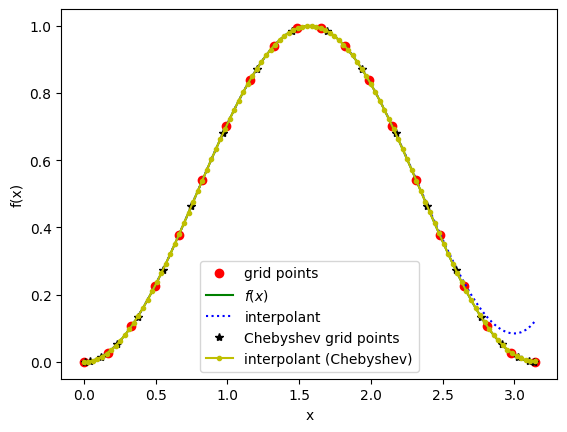

In [28]:
# Lagrange interpolation
import numpy as np
import math
from scipy.interpolate import lagrange
import matplotlib.pyplot as plt

# generate data points
def f(x):
    return np.sin(x)**2
    
# x_dis = np.array([0.0, 0.1, 0.2, 0.5, 1, 2, 2.3, 3, 3.14])  
x_dis = np.linspace(0, np.pi, 20)
print(f"number of requested grid points: {len(x_dis)}")
f_dis = f(x_dis)

def chebyshev_nodes(n, a, b):
    return np.array([(a+b)/2. + (b-a) / 2. * np.cos((2.*k+1.)/(2.*n)*math.pi) for k in range(n)])
    # How does this implementation differ from the Chebyshev nodes defined above, and why?
x_cheby = chebyshev_nodes(len(x_dis), np.min(x_dis), np.max(x_dis))
f_cheby = f(x_cheby)

#plot grid points and function
plt.plot(x_dis, f_dis, "ro", label="grid points")
xc = np.linspace(0, np.pi, 100)
plt.plot(xc, f(xc), "g-", label="$f(x)$")

# construct and plot Lagrange interpolant
poly = lagrange(x_dis, f_dis)
plt.plot(xc, poly(xc), "b:", label="interpolant")

# construct and plot Lagrange interpolant
plt.plot(x_cheby, f_cheby, "k*", label="Chebyshev grid points")

poly = lagrange(x_cheby, f_cheby)
plt.plot(xc, poly(xc), "y.-", label="interpolant (Chebyshev)")

plt.legend()
plt.xlabel("x")
plt.ylabel("f(x)")

### Gaussian integration

Equipped with **Lagrange interpolation**, we can now evaluate the integral over the function $f(x)$ by integrating over the interpolating polynomial $y(x)$, i.e.

$$ 
\int_a^b f(x)dx = \int_a^b y(x)dx + \int_a^b E(x)dx 
$$

We first tend to the first term on the right-hand side of the equation and **discuss the error term later**. 

$$ 
\int_a^b y(x)dx = \sum_{i=1}^N f(x_i) \underbrace{\int_a^b l_i(x)dx}_{=w_i} = \sum_{i=1}^N w_i f(x_i)
$$

resulting in

$$ 
\boxed{
\int_a^b f(x)dx = \sum_{i=1}^N w_i f(x_i) + \int_a^b E(x)dx }
$$

with the **weights**

$$
\boxed{
w_i = \int_{a}^b l_i(x) dx ={1 \over \pi^\prime(x_i)}\int_{a}^b {\pi(x) \over x-x_i}dx}
$$

The next step is transforming the integration interval $(a,b)$ into a standard interval $(-1,+1)$ using [integration by substitution](https://en.wikipedia.org/wiki/Integration_by_substitution). This way, we can calculate the weights only once and use them for all integrations. 

#### Transformation to a standard interval

<img src="figures/Shift.png" style="width:500px;height:300px;" >

In general, the integration interval may be shifted and stretched. A simple transformation can map a general interval $(a,b)$ back to the standard interval $(-1,1)$ (or any other), i.e.,

$$ 
\tilde{x}(x) = {1 \over b-a}\left ( 2x - (b+a) \right ), 
$$ 

which maps $x = a$ to $\tilde{x} = -1$ and $x = b$ to $\tilde{x} = 1$ as it should. 

Inversely, 
$$ 
x(\tilde{x}) = \tilde{x} \frac{b-a}{2} + \frac{b+a}{2} \,.
$$

Let's test the (forward) transformation:

In [29]:
import pandas as pd
def transform(x, a=2, b=5):
    return (2*x - (b+a))/(b-a)
a, b = 2, 5
data = {}
xs = np.linspace(a, b, 5)
xtildes = transform(xs)
print(f"a: {a}; b: {b} (here, with {len(xs)} points)")
pd.DataFrame(data={"x": xs, "xtilde": xtildes})

a: 2; b: 5 (here, with 5 points)


,x,xtilde
0,2.00,-1.0
1,2.75,-0.5
2,3.50,0.0
3,4.25,0.5
4,5.00,1.0


We can now derive how the integral measures under this transformation (see [integration by substitution](https://en.wikipedia.org/wiki/Integration_by_substitution)). With 

\begin{align}
dx &= \frac{dx}{d\tilde{x}} d\tilde{x} =  {b-a\over 2} d\tilde{x}\,,
\end{align}

we find

$$
w_i = \int_{a}^b l_i(x) dx = \frac{b-a}{2} \int_{-1}^{+1} l_i(\tilde{x}) d\tilde{x}
$$

and thus

$$
\boxed{w_i^{(a,b)} = {b - a \over 2}w_i^{(-1,1)}} 
$$

We can change the domain of an integral from $(a,b)$ to the standard interval $(-1,1)$, and then use the standard weights $w_i^{(-1,1)}$ with just a factor. We do not have to calculate new weights. 

**Let's calculate the "standard" weights in the next section.**

### Calculating the grid points and associated weights
With the above in mind, we can now restrict ourselves to the **standard integration interval $[-1,1]$**.

To calculate the weights in this interval, we need to choose the polynomial $\pi(x)$ of degree $N$; i.e., the associated zeros $x_i$. 

It turns out convenient choices are orthogonal polynomials, in particular **Legendre polynomials** $P_N(x)$ for our standard integration interval $[-1,1]$, which is the domain Legendre polynomials are defined on. 

**Let's plot the few lowest Legendre polynomials using [`numpy.polynomial.Legendre()`](https://numpy.org/doc/stable/reference/generated/numpy.polynomial.legendre.Legendre.html):**

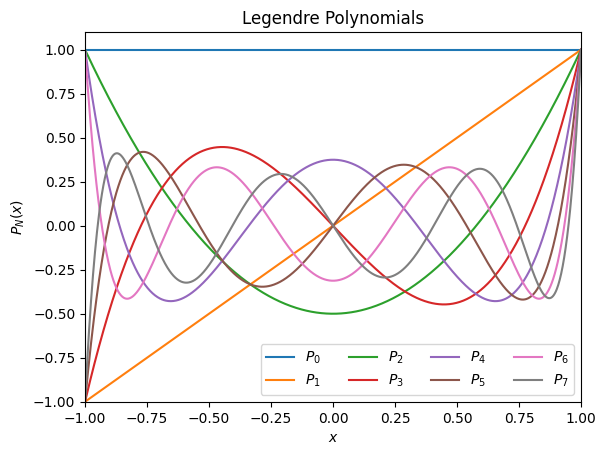

In [30]:
import matplotlib.pyplot as plt
import numpy as np

# import the module for Legendre Polynomials
from numpy.polynomial import Legendre as P

# generate PN
x = np.linspace(-1, 1, 1000)

# plot the Polynomial in its standard interval (-1,1)
for order in range(8):
    PN = P.basis(order)(x)
    plt.plot(x, PN, linestyle="-", label=f"$P_{order}$")
plt.xlim(-1,1)
plt.ylim(-1,1.1)
plt.xlabel("$x$")
plt.ylabel(r"$P_N(x)$")
plt.title("Legendre Polynomials")
plt.legend(loc="best", ncol=4)

#### Important properties of Legendre Polynomials

1.) Legendre polynomials $P_N(x)$ are **polynomials of degree $N$**, with $N$ **real-valued roots** $x_i$ in the interval $[-1,1]$
. For example,

\begin{align}
P_0(x) &= 1 \\
P_1(x) &= x \\
P_2(x) &= {1 \over 2} \left ( 3x^2 -1 \right )\\
P_3(x) &= {1 \over 2}\left ( 5x^3 - 3x \right ) \\
P_4(x) &= \frac{1}{8} \left(35x^4-30x^2+3\right)
\end{align}

2.) Legendre polynomials are **orthogonal** without a weight function, i.e.,

$$
\boxed{
\int_{-1}^{+1} P_n(x)P_m(x) = {2 \over 2n + 1}\delta_{nm}}
$$

3.) The Legendre polynomial $P_N(x)$ is orthogonal to all polynomials of degree $N-1$

$$
q(x) = \sum_{k=0}^{N-1}c_k x^k 
$$

since $q(x)$ can be represented as a **linear combination** of all Legendre polynomials with degrees less or equal than that of $q(x)$, i.e.

$$
\boxed{
\int_{-1}^{+1} q(x)P_N(x)dx = 0}
$$

**Let's check that the orthogonality of the lowest few Legendre Polynomials:**

In [31]:
import numpy as np
from numpy.polynomial import Legendre as P
from itertools import product

for i, j in product(range(5), repeat=2):
    f = lambda x: P.basis(i)(x) * P.basis(j)(x) * (2*i+1)/2  # see the equation above
    x, h = np.linspace(-1, +1, 2**6+1, retstep=True)
    res = romb(y=f(x), dx=h, show=False)
    print(f"(n, m) = ({i}, {j}) | integral: { 0 if np.isclose(res, 0) else res:.1f}")

(n, m) = (0, 0) | integral: 1.0
(n, m) = (0, 1) | integral: 0.0
(n, m) = (0, 2) | integral: 0.0
(n, m) = (0, 3) | integral: 0.0
(n, m) = (0, 4) | integral: 0.0
(n, m) = (1, 0) | integral: 0.0
(n, m) = (1, 1) | integral: 1.0
(n, m) = (1, 2) | integral: 0.0
(n, m) = (1, 3) | integral: 0.0
(n, m) = (1, 4) | integral: 0.0
(n, m) = (2, 0) | integral: 0.0
(n, m) = (2, 1) | integral: 0.0
(n, m) = (2, 2) | integral: 1.0
(n, m) = (2, 3) | integral: 0.0
(n, m) = (2, 4) | integral: 0.0
(n, m) = (3, 0) | integral: 0.0
(n, m) = (3, 1) | integral: 0.0
(n, m) = (3, 2) | integral: 0.0
(n, m) = (3, 3) | integral: 1.0
(n, m) = (3, 4) | integral: 0.0
(n, m) = (4, 0) | integral: 0.0
(n, m) = (4, 1) | integral: 0.0
(n, m) = (4, 2) | integral: 0.0
(n, m) = (4, 3) | integral: 0.0
(n, m) = (4, 4) | integral: 1.0


#### The Gaussian trick
Let's assume, for now, that the function $f(x)$ ("dividend") is a polynomial of degree $2N-1$ or less. Then we can write the polynomial $f(x)$ as

\begin{equation}  % \label{trick}
\boxed{f(x) = P_N(x)q(x) + r(x)}
\end{equation}

with the quotient $q(x)$ and remainder $r(x)$ polynomials of degree $N-1$ (or less). In other words, $q(x)$ and $r(x)$ are defined by [**polynomial division**](https://en.wikipedia.org/wiki/Polynomial_long_division). 

**Note that the degree of the remainder is always less than that of the divisor;** hence, the degree of $r(x)$ must be $N-1$ or less.

**While the following doesn't rise to the standard of rigorous proof of the above, it motivates why it is correct.** 

Let's say $f(x)$ is a polynomial of degree $9=2\times5 -1$, i.e., $N=5$, and the "divisor" polynomial $P_N(x)$ is of degree $N=5$, i.e., $P_5(x)$, then the quotient polynomial $q(x)$ must be of degree $N-1 = 4$ as well because the product of polynomials of degree $5$ and $4$ make a polynomial of degree $9$. 

What is to be determined is the polynomial $q(x)$. Since it is of degree $4$, we have 5 coefficients to choose, i.e. $q(x) = q_0 + q_1x +q_2x^2 + q_3x^3 + q_4x^4$. We can choose those coefficients such that the coefficients of the 5 highest powers of $f(x)$ match those of $P_N(x)q(x)$ and the others cancel.

The remaining powers $x^0,x^1,x^2,x^3,$ and $x^4$ of $f(x)$ and $P_N(x)q(x)$ remain unmatched and have to be matched with the remainder $r(x)$. **Hence, $r(x)$ must be a polynomial of order polynomial $N-1=4$.** 

Integrating over the standard interval, i.e.,

$$
\int_{-1}^1 f(x) dx = \int_{-1}^1 P_N(x)q(x) dx + \int_{-1}^1 r(x)dx
$$

the first term on the right hand side vanishes since $P_N(x)$ and $q(x)$ are orthogonal and thus

$$
\int_{-1}^1 f(x) dx = \int_{-1}^1 r(x)dx = \sum_{i=1}^N w_i r(x_i) \,,
$$

where the second term on the right-hand-side is an **exact representation** of $r(x)$ in the integrated function via Lagrange interpolation (because it is a polynomial of degree $N-1$) and thus an exact representation of the full integral, i.e., no error. 

This still is an inconvenient expression since it requires a polynomial division to find $r(x)$. We can get around this by using the boxed equation above at the grid points $x_i$, which are the roots of $P_N(x)$, i.e.,

$$
f(x_i) = \underbrace{P_N(x_i)}_{=0}q(x_i) + r(x_i) = r(x_i)
$$

and hence the expression

$$
\boxed{
\int_{-1}^1 f(x) dx = \sum_{i=1}^N w_i r(x_i) = \sum_{i=1}^N w_i f(x_i)}
$$

which is **exact** if $f(x)$ is a polynomial with a degree less or equal $2N-1$. 

**At this point, the grid $x_i$ points are _no longer arbitrary_ as they are chosen to be the roots of $P_N(x)$.**

In summary, using Legendre polynomials $P_N(x)$ for the Lagrange interpolation with their $N$ roots $x_i$ as grid points, we can **exactly calculate integrals of polynomials of degree $2N-1$ or less**. This means that, in this case, the (approximation) error vanishes.

As a consequence, for general functions $f(x)$, the error of the integral is much less than estimated for the Lagrange interpolation:

$$ \boxed{
\int_{-1}^1 E(x)dx = {f^{(2N)}(\xi) \over (2N)!}\int_a^b \pi^2(x)dx }
$$

#### The weights for Gauss-Legendre quadrature
The idea is quite simple. Since the polynomial $\pi(x)$ of order $N$ with $N$ roots can be written as

$$ 
\pi(x) = (x - x_1)(x - x_2)\dots (x - x_N) 
$$

it becomes, up to a prefactor $A_N$, identical with the Legendre polynomials $P_N(x)$ **if the grid points $x_i$ are chosen as the roots of $P_N(x)$**. 

Since the Legendre polynomials, defined by the [Rodrigues formula](https://en.wikipedia.org/wiki/Rodrigues%27_formula)

$$ 
P_N(x) = {1 \over 2^N N!}{d^N \over dx^N}(x^2 - 1)^N 
$$

have the prefactor of the highest power $x^N$

\begin{align}
A_N &= \frac{1}{N!} \frac{d^N}{dx^N} P_N(x) \\
&=  \frac{1}{2^N(N!)^2} {d^{2N} \over dx^{2N}}(x^2 - 1)^N \\
&= \frac{1}{2^N(N!)^2} {d^{2N} \over dx^{2N}} \sum_{k=0}^\infty  {N \choose k} x^{2(N-k)} (-1)^k\\
&= {(2N)! \over 2^N (N!)^2}
\end{align}

and $\pi(x)$ has the prefactor $1$ of the highest power $x^N$, we have 

$$ 
\boxed{\pi(x) = {P_N(x)\over A_N}}
$$

Note that we used the [**binomial theorem**](https://en.wikipedia.org/wiki/Binomial_theorem#Statement).

The weights now become

$$ 
w_i = \int_{-1}^1 l_i(x)dx = 
\int_{-1}^1 {\pi(x) \over \pi^\prime(x_i) (x - x_i)}dx 
= {1 \over P^\prime_N(x_i)} \int_{-1}^1 {P_N(x) \over ( x - x_i )}dx
$$

As a consequence of the [Christoffel-Darboux identity](https://mathworld.wolfram.com/Christoffel-DarbouxIdentity.html) for the Legendre polynomials, the weights become

$$
w_i = -{A_{N+1} \over A_N}{2 \over (2N+1)}{1\over P^\prime_N(x_i)P_{N+1}(x_i)}
$$

With $A_{N+1}/A_N = (2N+1)/(N+1)$ we then have

$$ \boxed{
w_i = -{2 \over N+1}{1\over P^\prime_N(x_i)P_{N+1}(x_i)} 
= {2 \over N P_{N-1}(x_i)P^\prime_N(x_i)}}
$$

where we have used for the last step the [Bonnet's recursion relation](https://en.wikipedia.org/wiki/Legendre_polynomials#Recurrence_relations)

$$
(n+1)P_{n+1}(x) = (2n+1)xP_n(x) - nP_{n-1}(x)~~,
$$

which becomes at the roots $x = x_i$ (i.e., $P_N(x_i) = 0$ in the first term vanishes) 

$$
(N+1)P_{N+1}(x_i) = -NP_{N-1}(x_i)~~.
$$

We now use the [differentiation rule](https://en.wikipedia.org/wiki/Legendre_polynomials#Recurrence_relations), i.e.

$$
(1 - x^2)P^\prime_n(x) = -nxP_n(x) + nP_{n-1}(x)
$$

at $x=x_i$, where $P_N(x_i) = 0$ where we find

$$
(1 - x_i^2)P^\prime_N(x_i) = NP_{N-1}(x_i)
$$

resulting finally in 

$$
\boxed{w_i = {2 \over (1-x_i^2) P^\prime_{N}(x_i)^2} }
$$

#### Error estimates

We have shown above that the error is given by

$$ \boxed{\varepsilon = {f^{(2N)}(\xi) \over (2N)!}\int_a^b \pi^2(x)dx }$$

With 

$$\pi(x) = {P_N(x) \over A_N}$$

the error becomes

$$ \varepsilon = {f^{(2N)}(\xi) \over A_N^2 (2N)!}\int_{-1}^1 P_N^2(x)dx $$

Given the expression for $A_N$ above, and the normalization

$$\int_{-1}^1P_N(x)P_N(x)dx = {2 \over 2N+1}$$

the final expression for the error is

$$ \boxed{\varepsilon = {2^{2N+1}(N!)^4 \over (2N+1)[(2N)!]^3}f^{(2N)}(\xi)}$$

where $\xi$ is some value in the interval $[-1,1]$. 

As mentioned above, if the function $f(x)$ to be integrated is a polynomial of degree $2N-1$ or less, the error vanishes as the interpolation becomes exact. 

### Gaussian quadrature with Python

`numpy` offers [Legendre](https://numpy.org/doc/stable/reference/generated/numpy.polynomial.legendre.Legendre.html) and other orthogonal polynomials as a class with attributes and methods, such as:

```python
from numpy.polynomial import Legendre as P
P.basis(i)(x)  # evaluates P_i (x)
P.basis(i).roots  # evaluates the roots of P_i (x)
PN.deriv(1)(x) # evaluates P'_i (x)
# and more
```

#### Roots of Legendre Polynomials
In order to implement **Gauss-Legendre quadrature**, we need to find the **roots of Legendre polynomials** since they serve as the grid points for the integration. 

[-9.49107912e-01 -7.41531186e-01 -4.05845151e-01 -1.05928677e-16
  4.05845151e-01  7.41531186e-01  9.49107912e-01] 7
[ 4.21884749e-15  6.10622664e-16 -6.66133815e-16  2.31718981e-16
  5.55111512e-17 -6.10622664e-16  3.33066907e-15]


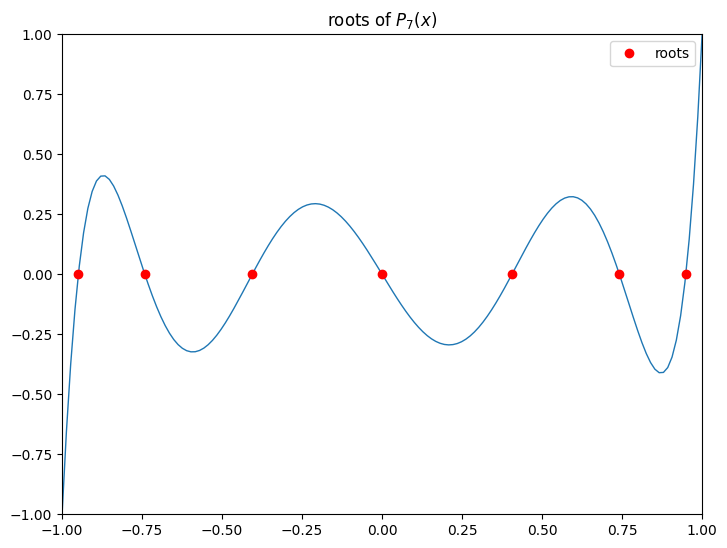

In [32]:
import matplotlib.pyplot as plt
import numpy as np

fig = plt.figure()
ax = fig.add_axes((0,0,1,1))
ax.set_xlim(-1,1)
ax.set_ylim(-1,1)

# import the module for Legendre Polynomials
from numpy.polynomial import Legendre as P

# generate PN of order `order`
order = 7
P = P.basis(order)

# use roots() method to find roots
roots = P.roots()
print(roots,len(roots))

# check accuracy of the roots
print(P(roots))

x = np.linspace(-1, 1, 150)
ax.plot(x, P(x), lw=1)
ax.plot(roots,np.zeros(len(roots)),'ro', label="roots")
ax.set_title(f"roots of $P_{order}(x)$")
ax.legend()

**Calculating the roots of high-order Legendre polynomials is computationally difficult and prone to numerical errors.** It's good advice to keep the order of the quadrature rule low and instead partition the integral into smaller intervals, each integrated using a low-order quadrature rule. For example:

$$
\int_a^d f(x) dx = \int_a^b f(x) dx + \int_b^c f(x)  dx + \int_c^d f(x)  dx
$$

with $a < b < c < d$.

#### Gaussian quadrature

Let's consider the integral:

$$
I = \int_{-1}^{+1} x^6 dx = \frac{2}{7} = 2.857...
$$

In [33]:
import matplotlib.pyplot as plt
import numpy as np
from numpy.polynomial import Legendre as P

def f(x):
    return x**6

def gaussquad(f,N):
    # generate Legendre Polynomial 
    PN = P.basis(N)

    # use roots() method to find roots
    roots = PN.roots()

    # calculate derivatives of P3 at the roots
    PN_prime = PN.deriv(1)(roots)

    # calculate the weights
    w=[]
    for i in range(0,N,1):
        w.append((2/(1-roots[i]**2))/(PN_prime[i])**2)
    
    func = f(roots)
    integral = np.dot(func, w)
    
    return integral

w = gaussquad(f, N=3)
exact_value = 2/7 
print(f"integral = {w:1.15e}, error = {abs(w-exact_value):1.15e}")     

integral = 2.400000000000001e-01, error = 4.571428571428560e-02


Let's study whether the algorithm behaves as predicted.

We stated that a polynomial of degree $2N-1$ or less can be **exactly** integrated with $N$ grid points, i.e., the roots of the Legendre polynomial $P_N(x)$. 
Hence, to integrate $f(x) = x^6$ exactly, we need $N \geqslant 4$, i.e. $P_4(x)$.

In [34]:
w = gaussquad(f, 4)
print(f"integral = {w:1.15e}, error = {abs(w-exact_value):1.15e}") 

integral = 2.857142857142855e-01, error = 1.665334536937735e-16


**Note that the integration range is fixed, $[-1,+1]$.**

#### Here a more general Gauss quadrature with arbitrary integration intervals

In [35]:
import matplotlib.pyplot as plt
import numpy as np
from numpy.polynomial import Legendre as P

def f(x):
    return np.exp(x)

def gaussquad(f, a, b, N, ret_grid_weights=False):
    PN = P.basis(N)
    roots = PN.roots()
    PN_prime = PN.deriv(1)(roots)  # evaluate the P'_N(x_i)

    w=[]
    for i in range(0,N,1):
        w.append((2/(1-roots[i]**2))/(PN_prime[i])**2)

    roots_transformed = 0.5*(b-a) * roots + 0.5*(a+b)
    weights_transformed = 0.5*(b-a) * np.array(w)

    func = f(roots_transformed)
    integral = np.dot(func,weights_transformed)
    
    if ret_grid_weights:
        return integral, roots_transformed, weights_transformed
    else:
        return integral

a=0; b=5
exact = np.exp(b)-1
I = gaussquad(f, a=a, b=b, N=10)
print(f"integral = {I:1.15e} , error = {abs(I-exact):1.15e}")

integral = 1.474131591025775e+02 , error = 8.810729923425242e-13


**How are the grid points (i.e., roots of $P_N(x)$) distributed?** They are dense near the boundaries of the integral, and less dense at the center of the integration interval, as the following histogram shows:

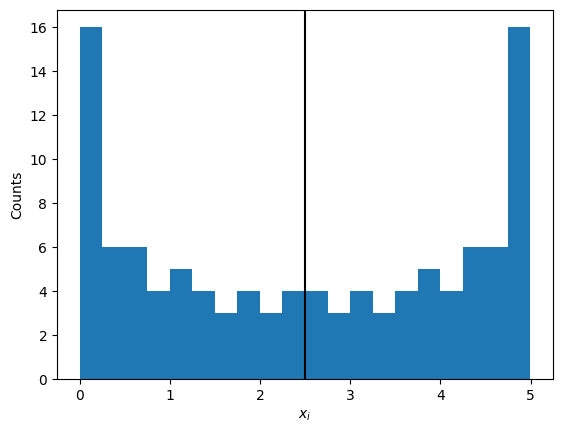

In [36]:
import matplotlib.pyplot as plt
b=5
N=110
I, xi, wi = gaussquad(f, a=0, b=b, N=N, ret_grid_weights=True)
plt.hist(xi, bins=20)
plt.axvline((a+b)/2, c="k")
plt.ylabel("Counts")
plt.xlabel("$x_i$")
if N < 10:
    print("grid points", xi)
    print("mirrored grid point", np.flip(b-xi))

They are also symmetric around the center point $(b+a)/2$ (black vertical line), which is on the grid if $N$ is odd. Why?

#### Gaussian quadrature with Scipy 

[Gaussian quadrature](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.fixed_quad.html#scipy.integrate.fixed_quad) is implemented in `scipy`. You can use it as follows:

```Python
from scipy.integrate import fixed_quad

fixed_quad(func, a, b, args=(), n=5)
```

Let's give it a try:

In [37]:
from scipy.integrate import fixed_quad
fixed_quad(func=f, a=a, b=b, args=(), n=15)

(np.float64(147.41315910257669), None)

What is the purpose of the `args` argument?

## Related quadrature rules

The integration problem we discussed so far can be expressed in a slightly more general way by introducing a positive weight function $g(x)$ into the integrand, and allowing an interval other than $[−1, 1]$. That is, the problem is to calculate

$$ \int_a^b \omega(x)\,f(x)\,dx $$

for some choices of $(a,b)$, and $\omega(x)$. For $\omega(x)=1$, the problem is the same as that considered above (i.e., Gauss-Legendre quadrature). Other choices lead to other integration rules, including [these](https://en.wikipedia.org/wiki/Gaussian_quadrature#Other_forms):

<img src="figures/quadrature_rules.png" style="width:680px;" >

For instance, let's discuss **Gauss–Laguerre quadrature** (not to be confused with Gauss-Legendre quadrature). It allows for approximating the value of integrals of the following kind:

$$\int_{0}^{+\infty} e^{-x} f(x)\,dx.$$

In this case (i.e. $\omega(x) = e^{-x}$)

$$\boxed{\int_{0}^{+\infty} e^{-x} f(x)\,dx \approx \sum_{i=1}^n w_i f(x_i)}$$

where $x_i$ $i$-th root of the [Laguerre Polynomial](https://en.wikipedia.org/wiki/Laguerre_polynomials) $L_i(x)$ and the weight $w_i$ is given by:

$$ w_i = \frac {x_i} {\left(n + 1\right)^2 \left[L_{n+1}\left(x_i\right)\right]^2}.$$

`numpy` provides an implementation of the Gauss-Laguerre grid points and associated weights:

In [38]:
from numpy.polynomial.laguerre import laggauss
x, w = laggauss(10)
for x, w in zip(x,w):
    print(f"x = {x},\tw = {w}")

x = 0.1377934705404926,	w = 0.3084411157650174
x = 0.729454549503171,	w = 0.40111992915527606
x = 1.808342901740316,	w = 0.21806828761180952
x = 3.4014336978548996,	w = 0.062087456098677836
x = 5.552496140063804,	w = 0.009501516975181099
x = 8.330152746764497,	w = 0.0007530083885875413
x = 11.843785837900066,	w = 2.8259233495995625e-05
x = 16.279257831378104,	w = 4.249313984962682e-07
x = 21.99658581198076,	w = 1.8395648239796286e-09
x = 29.92069701227389,	w = 9.911827219609027e-13


## Numerical integration over infinite ranges
At this point we considered numerical integration of either functions or functions given by discrete data over a finite range. While data are always over finite domain, functions may not be. For example we may want to integrate

$$I = \int_0^\infty \exp(-x^2) dx $$

which is known to be a special function called the *error function*. 

Note that **Gauss-Hermite quadrature** would be well-suited to evaluate this squared-exponential type integral. However, let's keep the discussion of semi-definite integrals more general at this point.

One could argue, that since the exponential functions falls off rather quickly one just imposes a **cutoff** (cutoff regularization) and makes sure that the cutoff doesn't affect the value of the integral within the required accuracy. One has to check very carefully that the results are insensitive to the used cutoff value.

But there are more systematic ways to deal with such situations that are based on **transformations of the integration variable**, here $x$. There are numerous options for these transformation and they are described in your textbook. We use for our example

$$\boxed { z\equiv {x \over 1+x}}$$

so that $x=0$ maps onto $z=0$, and $x = \infty$ maps onto $z=1$. To transform $dx$ into $dz$, we need the Jacobian $dx/dz$

$$x = {z \over 1-z} ~~~{\rm and}~~~ {dx \over dz} = {1 \over (1- z)^2} \Rightarrow dx = {1 \over (1-z)^2}dz$$

In summary

$$\int_0^\infty \exp(-x^2) dx = \int_0^1 \exp  \left (- {z^2 \over (1-z)^2} \right ) {1 \over (1-z)^2}dz $$

Inspecting this integral the old rule applies - **there is no free lunch**. The problem with the infinite interval has morphed into yet another problem and that is divisions by zero. Note that, e.g., the grids for Gauss-Legendre quadrature do not include the boundaries.

At $z=1$, the exponent is zero as well as the numerator - so we divide 0 by 0. **Since the exponent is approaching zero much faster than the polynomial, the integrand is actually $0$ at $z=1$.** 

We will have to take this into account when we provide values for the integrand at the integration limit $z=1$, i.e. we will set the value of the integrand at $z=1$ to zero. At the other limit, the integrand is well-behaved and has the value of $1$. 

Lets us the **adaptive Trapezoidal algorithm**:

In [39]:
import numpy as np

# (scaled) integration interval
a=0; b=1; N1=100  # Question: why do we integrate here from a=0 to b=1?
N2=2*N1

# define the function to be integrated
def f(x): 
    """rescaled integrand function"""
    return np.exp(-(x**2/(1-x)**2)) / ((1-x)**2)

# define the Trapezoidal program as a function
def trapezoidal(f,a,b,N):
    h=(b-a)/N
    x=np.arange(a+h,b,h)
    y=f(x)
    return 0.5*h*(f(a) + 0)+sum(y)*h
    # note that we have set here f(b \to \infty) = 0

# maximum error
error_max=1e-7
#
I1=trapezoidal(f,a,b,N1)
I2=trapezoidal(f,a,b,N2)
error = (1./3.)*abs((I2-I1))
print("N = %d , Integral = %1.16e, error = %1.16e"%(N2,I1,error))
while error > error_max:
    I1=I2
    N1=N2
    N2=2*N1
    I2=trapezoidal(f,a,b,N2)
    error=(1./3.)*abs((I2-I1))
    print("N =", N2,I2,error)
true_error = np.abs(np.sqrt(np.pi)/2 - I2)
print(f"estimate = {I2:1.15e}, est. error = {error:1.15e}, true error = {true_error:1.15e}")

N = 200 , Integral = 8.8621025878613502e-01, error = 4.1666666523350786e-06
N = 400 0.8862258837860917 1.0416666665532166e-06
N = 800 0.8862266650360909 2.6041666641625955e-07
N = 1600 0.8862268603485901 6.510416639127214e-08
estimate = 8.862268603485901e-01, est. error = 6.510416639127214e-08, true error = 6.510416783456208e-08


Note that the true value of the (Gaussian integral) is:
$$
I = \frac{\sqrt{\pi}}{2} \approx 0.8862269 \,.
$$

## Cauchy Principal value Integrals

[Cauchy principal value integral](https://en.wikipedia.org/wiki/Cauchy_principal_value) allow us to assigned values to otherwise ill-defined integrals. For a singularity at $x = b$, it's defined as follows:

$$\mathcal{P} \int \limits_a^c f(x) = \lim_{ \; \varepsilon \to 0^+ \;} \, \left[ \, \int_a^{b-\varepsilon} f(x) \, \mathrm{d}x ~ + ~ \int_{b+\varepsilon}^c  f(x) \, \mathrm{d}x \, \right]$$

with $a < b < c $.

For example, let's consider:
$$\mathcal{P} \int_{-1}^1\frac{\mathrm{d}x}{x} = \lim_{a \to 0+}\left(\int_{-1}^{-a}\frac{\mathrm{d}x}{x} + \int_a^1\frac{\mathrm{d}x}{x}\right)=0.$$

For more examples, e.g., see [here](https://en.wikipedia.org/wiki/Cauchy_principal_value#Examples). Note the corresponding regular integral (i.e., without the principle value $\mathcal{P}$) does not exist.

Let's consider integrals of the following, common type:

\begin{equation} 
I = {\cal P} \int_0^{\infty} \frac{f(x)}{x^2 -x_0^2}
\end{equation} 

**How can we evaluate this principal value integral?**

The common trick is to convert it to a regular integral by subtracting the pole at $x_0$.
To this end, one recognizes that
$$
A \, \mathcal{P} \int_0^\infty \frac{dx}{x^2-x_0^2} = 0 \quad \mathrm{for\ arbitrary\ scalar\ } A
$$

Next, we add this zero to $I$ with $A=-f(x_0)$ without changing its value:

$$
I = \mathcal{P} \int_0^\infty dx \frac{f(x)}{x^2-x_0^2} = \boxed{\int_0^\infty dx \frac{f(x)-f(x_0)}{x^2-x_0^2} = I}
$$

The result is a regular integral (boxed) that we can evaluate using the quadrature rules discussed in the lecture. However, one has to be careful with numerical instabilities if the grid points get too close to the pole.

## Double and multiple integrals 
Sometimes we need to integrate a function of two variabels over a domain in the $xy$ plane. The general form of
such integral reads:

$$\boxed{ I = \int_{x_0}^{x_1} dx \int_{g(x)}^{h(x)} dy f(x,y) }$$

Note that the integration limits in one variable may depend on the other variable depending on the
area in the $x$-$y$ plane one has to integrate over

For example, we may integrate the function $f(x,y)$ over an elliptical domain described by the standard equation 

$$ {x^2 \over a^2} + {y^2 \over b^2} = 1$$

where $a$ and $b$ are the semi-major and semi-minor axes.

<img src="figures/Double-integral.png" style="width:500px;height:400px;" >

In this case, we first integrate over $y$ in intervals that depend on the value of $x$, i.e.

$$ -b\sqrt{1 - {x^2\over a^2}} < y < b\sqrt{1 - {x^2\over a^2}}$$

and $x$ runs from $-a$ to $a$. Hence, here specifically

$$ I = \int_{-a}^{a} dx \int_{-b\sqrt{1 - {x^2\over a^2}}}^{b\sqrt{1 - {x^2\over a^2}}} dy f(x,y)$$

Double integrals with curved boundaries are **not an easy numerical task** unless one can calculate them analytically with the use of e.g. curve linear coordinate systems such as polar or elliptic coordinates. 

While there is no known optimal choice of grid points, Gaussian quadrature works well because these grid points are not on the boundaries. 

### Double integral using Gaussian quadrature

We can use [`dblquad()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.dblquad.html),

```Python
scipy.integrate.dblquad(func, a, b, gfun, hfun, args=(), epsabs=1.49e-08, epsrel=1.49e-08)
```

to solve the double integral

$$ \int_a^b dx \int_{g(x)}^{h(x)}f(x,y) dy $$

It is a 2 dimensional version of Gaussian quadrature, which provides error estimates.

In [40]:
from scipy.integrate import dblquad
import numpy as np

def f(x,y):
    return 1

# upper integration limit of y integration
def upper_limit(x):
    return b*np.sqrt(1-x**2/a**2)

# lower integration limit of y integration
def lower_limit(x):
    return -b*np.sqrt(1-x**2/a**2)

# define the elliptic domain and integrate
a=2;b=1
integral = dblquad(f,-a,a,lower_limit,upper_limit)
print(f"integral: {integral[0]:e}; estimated error: {integral[1]:e}; true error: {np.abs(integral[0]-np.pi*a*b):e}")

integral: 6.283185e+00; estimated error: 4.000944e-09; true error: 1.065814e-14


## Example: Gravitational pull of a uniform sheet

<img src="figures/sheet.png" width="480" >


A uniform square sheet of metal lies in the $x-y$ plane with side length $2L$. With Newton's law of gravitation, the force of a small piece of the sheet (in the $z$-direction) on a test mass $m$ at distance $z$ above the origin is:

\begin{align*}
dF_z &= \frac{G \, m \, dM \, \cos \theta}{r^2}\\
dM &= \frac{M dS}{A} = \sigma \, dx \, dy \\
\cos \theta &= \frac{z}{|r|}\\
r &= \left( x^2 + y^2 + z^2 \right)^{1/2}
\end{align*}

with the 2D mass density $\sigma$, the area $A = (2L)^2$, and the gravitational constant $G$.

The force per test mass is then given by:

$$\boxed{
\frac{F_z}{m} = G\sigma z \int_{-L}^L dx \int_{-L}^L dy {1 \over \left ( x^2 + y^2 + z^2 \right )^{3/2}}
}
$$


### Making variables dimensionless
Ideally, we like to integrate over variables that have no units. The length variables $x,y,z$ have the unit length. We have to find a characteristic length by which we *scale* those variable. **The half width of the plate $L$ is a possible choice:**

$$
\bar{x}=x/L~~,~~\bar{y}=y/L~~,~~\bar{z}=z/L
$$

With those variables the integral becomes

$$
\frac{F_z}{m} = G\sigma \bar{z} \int_{-1}^1 d\bar{x} \int_{-1}^1 d\bar{y} {1 \over \left ( \bar{x}^2 + \bar{y}^2 + \bar{z}^2 \right )^{3/2}} 
$$

and hence we can scale the force with the remaining prefactors to find

$$
\bar{F}_z \equiv {F_z \over G\sigma m} = \bar{z} \int_{-1}^1 d\bar{x} \int_{-1}^1 d\bar{y} {1 \over \left ( \bar{x}^2 + \bar{y}^2 + \bar{z}^2 \right )^{3/2}} 
$$

Everything now is dimensionless and all numbers are of the same order. Note that since the gravitational constant is given by 

$$
G = 6.674\cdot 10^{-11} {Nm^2 \over kg^2}
$$

and the 2D mass density $\sigma$ has the dimension $kg/m^2$, the units of $G\sigma$ is just like $F_z$
$N/kg$, i.e force per kg of mass, and $\bar{F}_z$ is dimensionless.

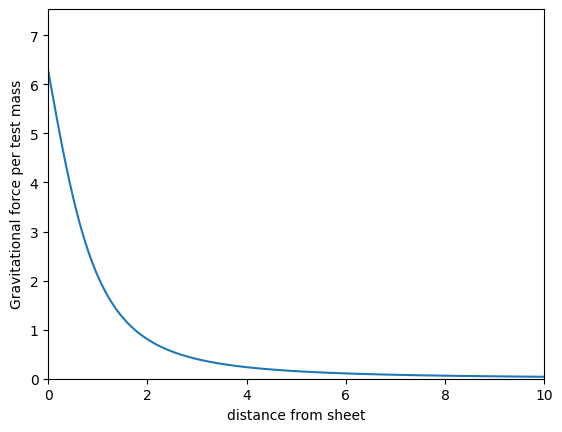

In [41]:
import numpy as np
from scipy.integrate import dblquad
import matplotlib.pyplot as plt

# define the function to be integrated
def f(x,y,z):
    return 1.0/pow(x**2+y**2+z**2, 1.5)

# we have to pass an additional parameter to the function
# to be integrated, which is done with *args=()*. The argument of args must, however,
# be a tuple and not a number

integral=[]
ranges = np.arange(0.001,10,0.001)
for z in ranges:
    out,error = dblquad(f, -1, 1, -1, 1, args=(z,))
    integral.append(z*out)

plt.plot(ranges,np.array(integral))
plt.xlim(0, 10)
plt.ylim(0, 1.2*max(integral))
plt.xlabel("distance from sheet")
plt.ylabel("Gravitational force per test mass")
plt.show()

### Triple integrals using the SciPy library

We can use [`tplquad()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.tplquad.html)

```Python
scipy.integrate.tplquad(func, a, b, gfun, hfun, qfun, rfun, args=(), epsabs=1.49e-08, epsrel=1.49e-08)
```

to solve the triple integral

$$ \int_a^b dx \int_{g(x)}^{h(x)}dy \int_{q(x,y)}^{r(x,y)}dz f(x,y,z)$$

It is a 3-dimensional version of Gaussian quadrature, which provides error estimates. 

Lets consider a simple example, we integrate a function $f(x,y,z)$ over a spherical volume with radius $r$, described
by

$$ x^2 + y^2 +z^2 = r^2 $$

We first integrate over $z$ within the integration limits $ \pm\sqrt{r^2 - x^2 -y^2}$. 

For given values of $x,y$ lying on a circle with radius $r$, i.e., the projection of the sphere onto the $x$-$y$-plane, we integrate $z$ between those limits. 
This results in a function $F(x,y)$ over a circle with radius radius $r$. 

Then we follow the same procedure we used for the two dimensional integral: We integrate over $y$ in the limits $\pm\sqrt{r^2 - x^2}$ for each value of $x$ resulting in a function $G(x)$ which we then integrate over $x$ in the limits $\pm r$.

$$ \int_{-r}^{r} dx \int_{-\sqrt{r^2 - x^2}}^{\sqrt{r^2 - x^2}}dy \int_{-\sqrt{r^2 - x^2 -y^2}}^{\sqrt{r^2 - x^2 -y^2}}dz f(x,y,z)$$

In [42]:
from scipy.integrate import tplquad
import numpy as np

def f(x,y,z):
    return 1

def upper_limit_z(x,y):
    return np.sqrt(r**2-x**2-y**2)

def lower_limit_z(x,y):
    return -upper_limit_z(x,y)

def upper_limit_y(x):
    return np.sqrt(r**2-x**2)

def lower_limit_y(x):
    return -upper_limit_y(x)

# define the radius and integrate
r = 2
integral, err = tplquad(f, -r, r,
                        lower_limit_y, upper_limit_y,
                        lower_limit_z,upper_limit_z, 
                        epsabs = 1e-8)
print(integral, err, np.abs(integral- (4/3)*np.pi*r**3))

33.51032163829119 8.00188892924325e-09 6.394884621840902e-14


Python has **lambda** functions. 

Normal functions return value calculated based on some inputs. `lambda` returns (anonymous) functions and can be defined within a program on the fly. 

In this context, they provide means for a more compact code as we don't have to define the functions for the integration limit as an external function. 

In [43]:
import scipy.integrate as integrate
import numpy as np

# define the spherical domain   
r = 2

# Use lambda functions to define the lower and upper limit functions. **lambda** returns
# the **function** "upper_limit_z" and not the value of it
upper_limit_z = lambda x,y: np.sqrt(r**2-x**2-y**2)
lower_limit_z = lambda x,y: -np.sqrt(r**2-x**2-y**2)
upper_limit_y = lambda x: np.sqrt(r**2-x**2)
lower_limit_y = lambda x: -np.sqrt(r**2-x**2)
integral, err = integrate.tplquad(lambda x,y,z: 1, 
                                  -r, r, 
                                  lower_limit_y, upper_limit_y, 
                                  lower_limit_z, upper_limit_z)
print(integral, err, np.abs(integral- (4/3)*np.pi*r**3))

33.51032163829119 8.00188892924325e-09 6.394884621840902e-14


## Libraries for numerical integration

While it is important to understand the various integration algorithms, it is generally a good idea to use the well-tested and written functions provided by libraries. 

`Python` offers a variety of functions:

1. Trapezoid integration (for sampled data sets): [`scipy.integrate.trapezoid()`](https://docs.scipy.org/doc/scipy-1.16.2/reference/generated/scipy.integrate.trapezoid.html)
2. Simpson integration (for sampled data sets): [`scipy.integrate.simpson()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.simpson.html)
3. Romberg integration (for sampled data sets): [`scipy.integrate.romb()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.romb.html) 
4. Gauss quadrature: [`scipy.integrate.fixed_quad()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.fixed_quad.html#scipy.integrate.fixed_quad)
5. **adaptive quadrature using QUADPACK in [`scipy.integrate`](https://docs.scipy.org/doc/scipy/reference/integrate.html#module-scipy.integrate):**
   - single integrals: [`quad`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.quad.html#scipy.integrate.quad)
   - double integrals: [`dblquad`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.dblquad.html#scipy.integrate.dblquad)
   - triple integrals: [`tplquad`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.dblquad.html#scipy.integrate.tplquad)
6. adaptive, deterministic cubature: [`cubature`](https://pypi.org/project/cubature/) (wrapper for the `C` code by Johnson et al.)
7. adaptive, deterministic and nondeterministic cubature: [PyCuba](https://johannesbuchner.github.io/PyMultiNest/pycuba.html) (wrapper for the `C` code by Hahn)

There are also various `C/C++` libraries:

1. adaptive, deterministic cubature: [Cubature](https://github.com/stevengj/cubature)
2. adaptive, deterministic and nondeterministic cubature: [Cuba](https://feynarts.de/cuba/)
3. [Boost](https://www.boost.org/doc/libs/1_83_0/libs/math/doc/html/quadrature.html) implements various methods
4. [GSL](https://www.gnu.org/software/gsl/doc/html/integration.html) implements various methods

Go-to method (and it's higher-order counterparts):

```python
quad(func, a, b, args=(), full_output=0, epsabs=1.49e-08, epsrel=1.49e-08, limit=50, points=None, weight=None, wvar=None, wopts=None, maxp1=50, limlst=50, complex_func=False)
```

From `scipy`'s [documentation](https://github.com/scipy/scipy/blob/f3ebcf8b4f1e559feb3e2db8aa2f2f433bcff0f3/scipy/integrate/quadpack.py#L101):
> For **finite integration limits**, the integration is performed using a [**Clenshaw-Curtis method**](https://en.wikipedia.org/wiki/Clenshaw%E2%80%93Curtis_quadrature) which uses Chebyshev moments.     
> ...     
> If one of the integration limits is infinite, then a Fourier integral is
  computed (assuming w neq 0).

Note: later in this lecture series, we will discuss the Fourier transform in detail, which is related to the mentioned Clenshaw-Curtis method.

In [44]:
from scipy import integrate
y = lambda x: x**4 - x**2 + np.sin(x)**2
integrate.quad(y, -1, 1)